In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:

!git clone https://github.com/SkalskiP/yolov9.git
%cd yolov9
!pip install -r requirements.txt -q

Cloning into 'yolov9'...
remote: Enumerating objects: 325, done.
remote: Counting objects: 100% (325/325), done.
remote: Compressing objects: 100% (152/152), done.
remote: Total 325 (delta 165), reused 264 (delta 162), pack-reused 0
Receiving objects: 100% (325/325), 2.23 MiB | 7.48 MiB/s, done.
Resolving deltas: 100% (165/165), done.
/content/yolov9
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 72.6 MB/s eta 0:00:00


In [ ]:
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-e.pt
#!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-c.pt
#!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-e.pt


In [ ]:
%cd {HOME}/yolov9

/content/yolov9


In [ ]:
!mkdir -p {HOME}/data

In [ ]:
import torch
torch.cuda.empty_cache()

In [ ]:
import gc

globals()['variables'] = []
del globals()['variables']
gc.collect()

0

In [ ]:
%env PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True

env: PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True


In [ ]:
%cd {HOME}/yolov9

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="1abKaHE6R8s1OAmdlWLh")
project = rf.workspace("machine-learning-joann").project("cancer-w0t8n")
version = project.version(7)
dataset = version.download("yolov9")



/content/yolov9
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cancer-7 in yolov9:: 100%|██████████| 1990/1990 [00:00<00:00, 5250.79it/s]


# Train Custom Model

In [10]:
%cd {HOME}/yolov9

!python train_dual.py --workers 8 --patience 400 --device 0 --batch 8 --data '/content/yolov9/cancer-7/data.yaml' --img 640 --cfg models/detect/yolov9-e.yaml --weights '/content/weights/yolov9-e.pt'  --hyp hyp.scratch-high.yaml --min-items 0 --epochs 600 --close-mosaic 15

/content/yolov9
2024-04-26 04:08:01.856386: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-26 04:08:01.856440: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-26 04:08:01.858064: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-26 04:08:02.931855: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
train_dual: weights=/content/weights/yolov9-e.pt, cfg=models/detect/yolov9-e.yaml, data=/content/yolov9/cancer-7/data.yaml, hyp=hyp.scratch-high.yaml, epochs=600, batch_size=8, imgsz=640, rect=False, resume=False, nosave=Fals

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# save pipe.pkl to output data folder
#!cp -r <custom_training> /content/drive/MyDrive/<rcnn result>
!cp -r '/content/yolov9/runs/train/yolov9-e-finetuning3' /content/drive/MyDrive/<rcnn result>

/bin/bash: -c: line 1: syntax error near unexpected token `newline'
/bin/bash: -c: line 1: `cp -r '/content/yolov9/runs/train/yolov9-e-finetuning3' /content/drive/MyDrive/<rcnn result>'


# Examine Training Results

In [11]:
!ls /content/yolov9/runs/train/exp/

confusion_matrix.png				    PR_curve.png	   val_batch0_pred.jpg
events.out.tfevents.1714104483.56c50bda8a80.3927.0  R_curve.png		   val_batch1_labels.jpg
F1_curve.png					    results.csv		   val_batch1_pred.jpg
hyp.yaml					    results.png		   val_batch2_labels.jpg
labels_correlogram.jpg				    train_batch0.jpg	   val_batch2_pred.jpg
labels.jpg					    train_batch1.jpg	   weights
opt.yaml					    train_batch2.jpg
P_curve.png					    val_batch0_labels.jpg


# Run the following code to view your training graphs:

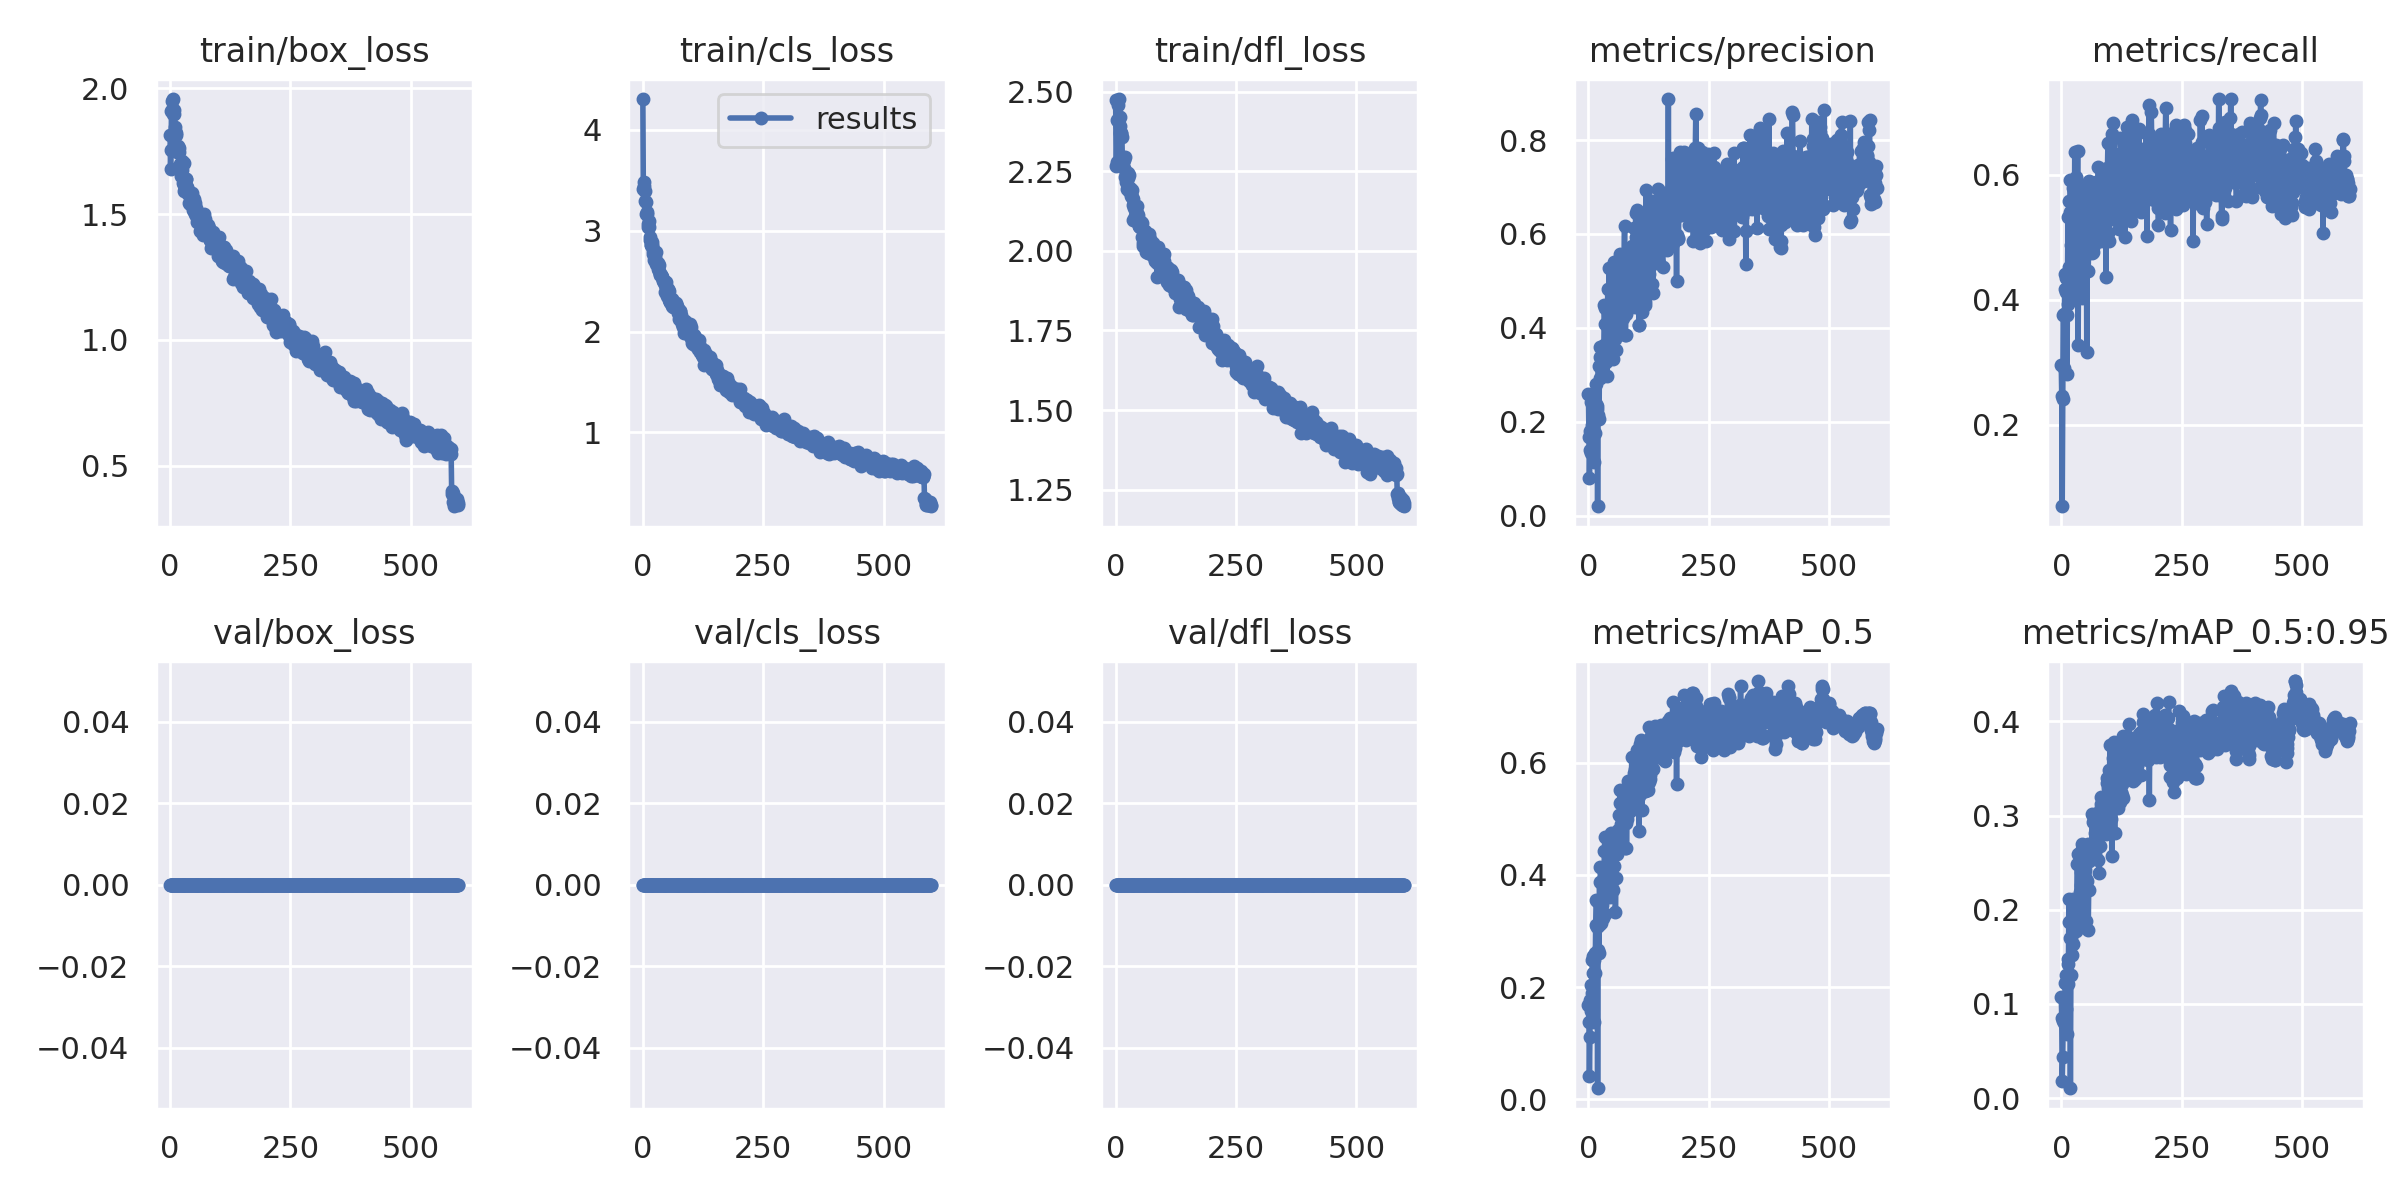

In [34]:

from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/results.png", width=1000)

In [ ]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/results.png", width=1000)

# Run the following code to view your confusion matrix:

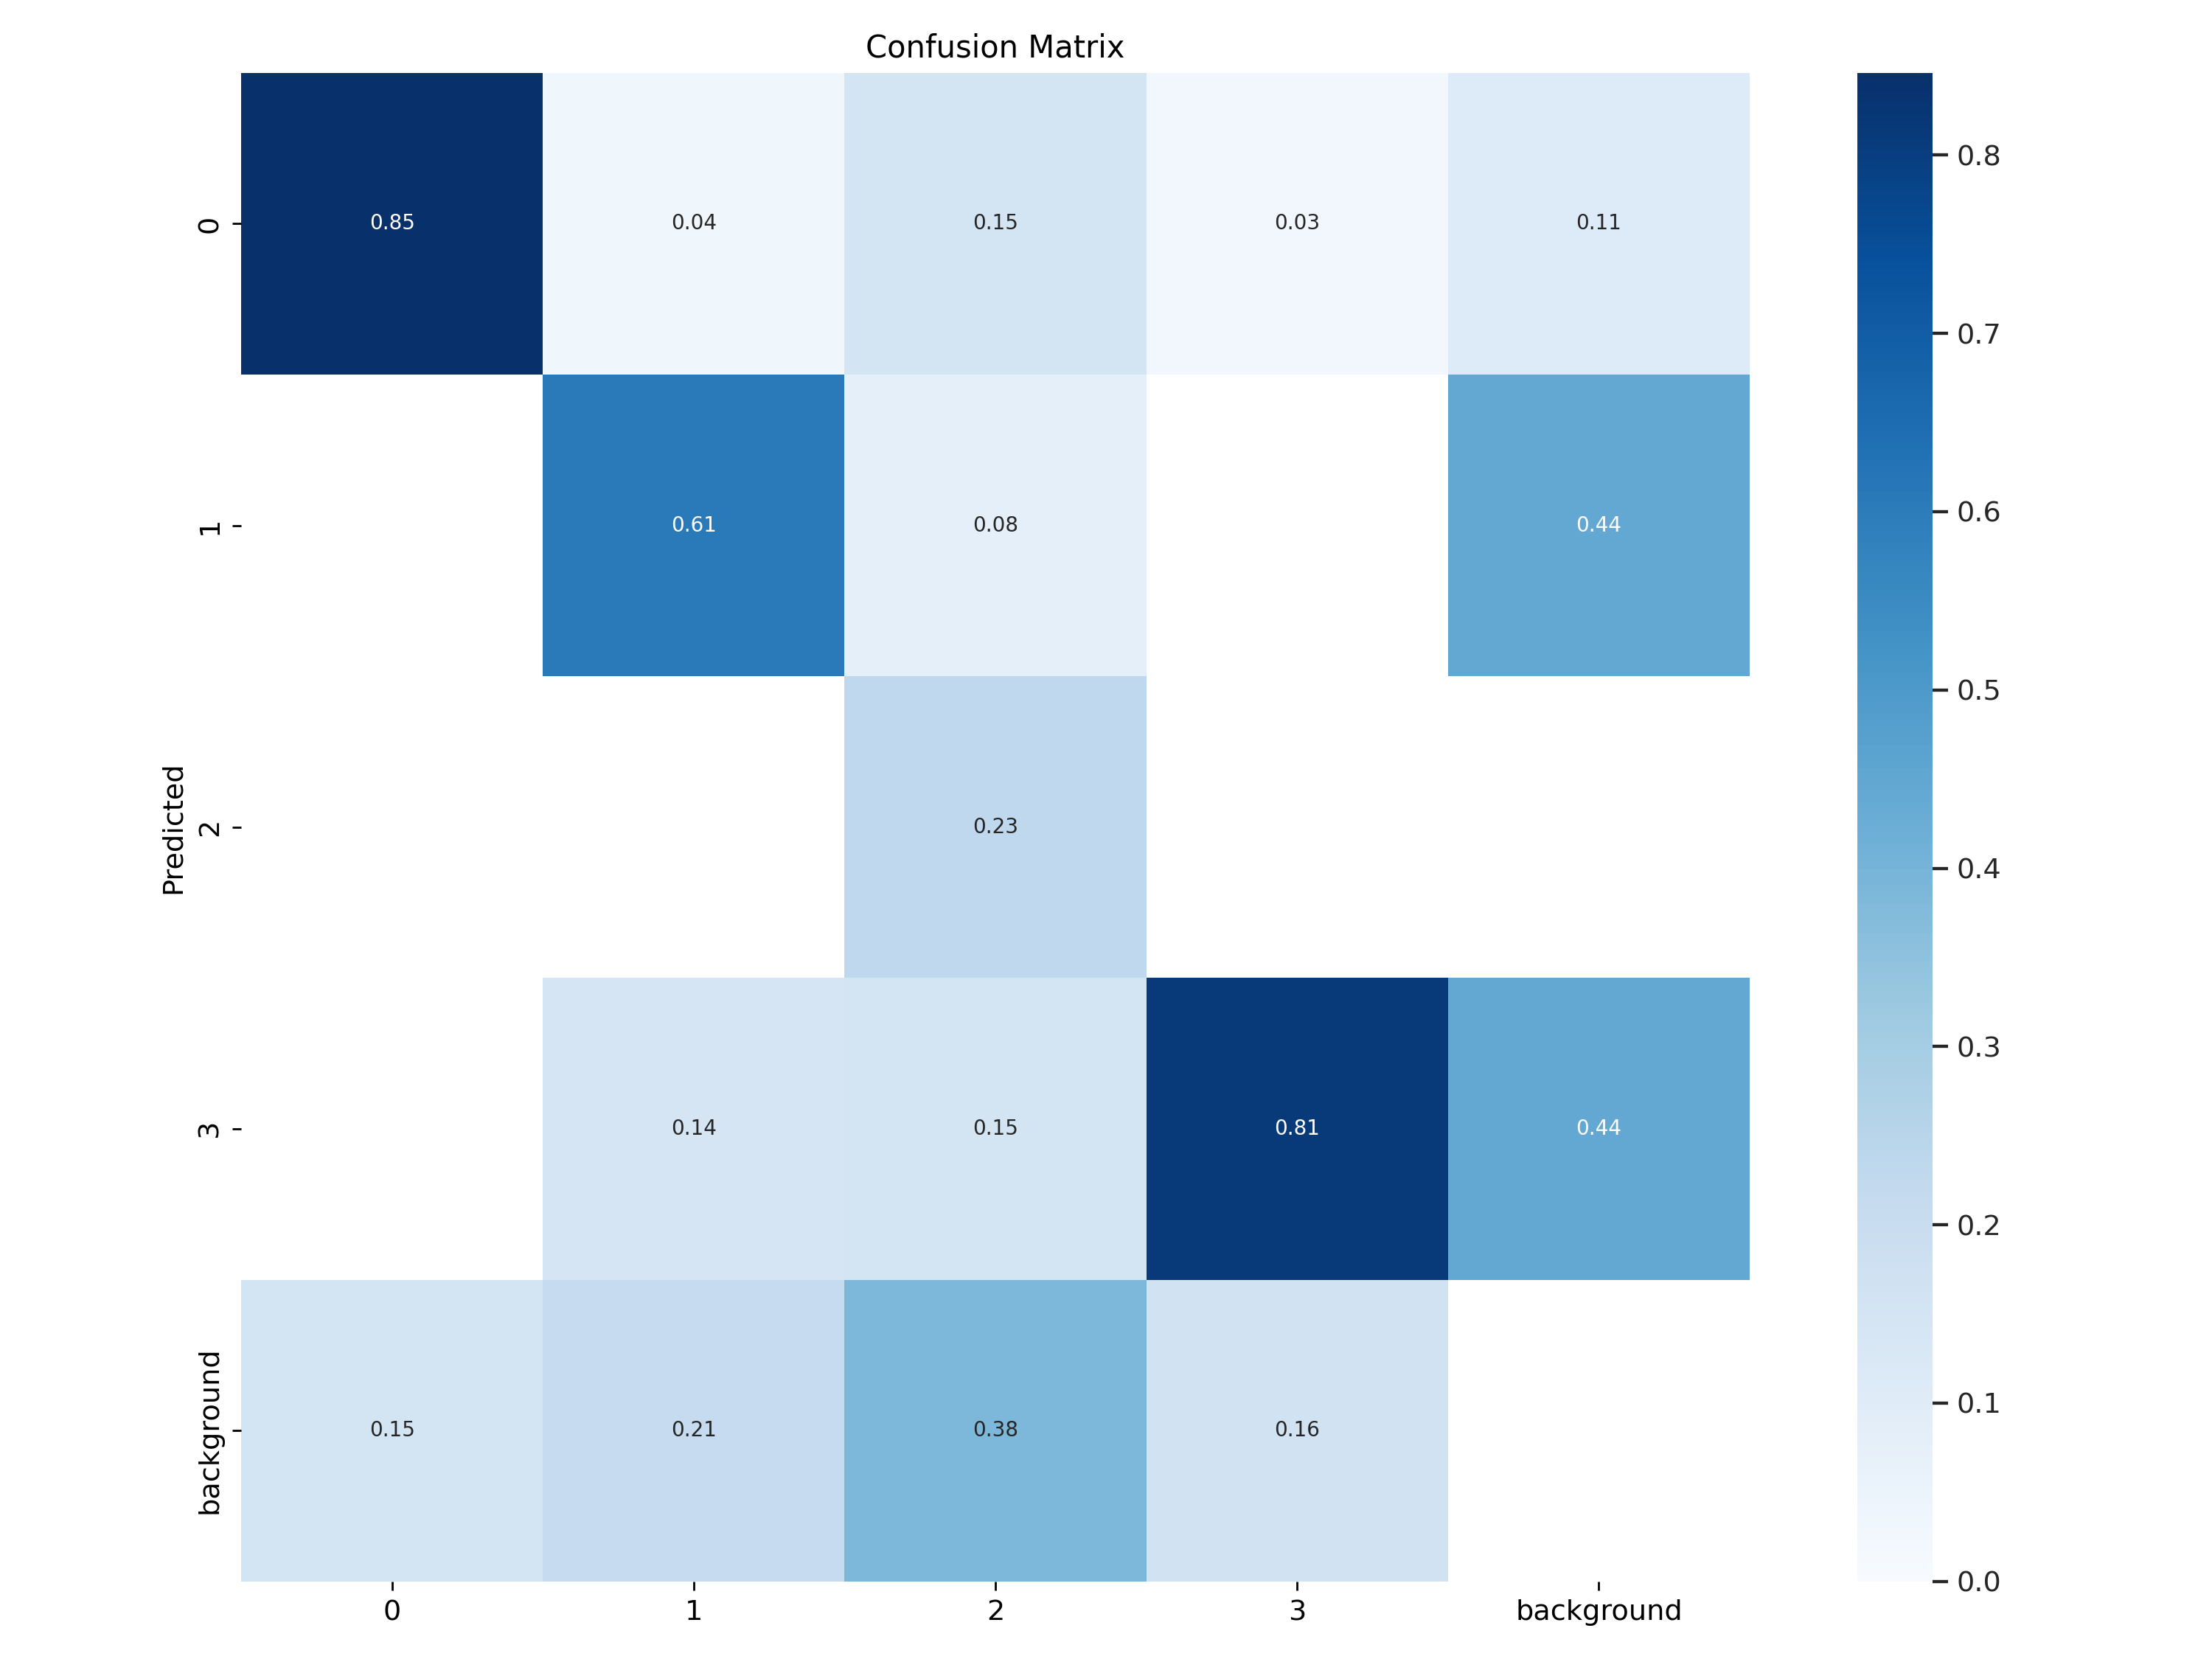

In [13]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/confusion_matrix.png", width=1000)

# Run the following code to see results from your model on a batch of images in your validation set:

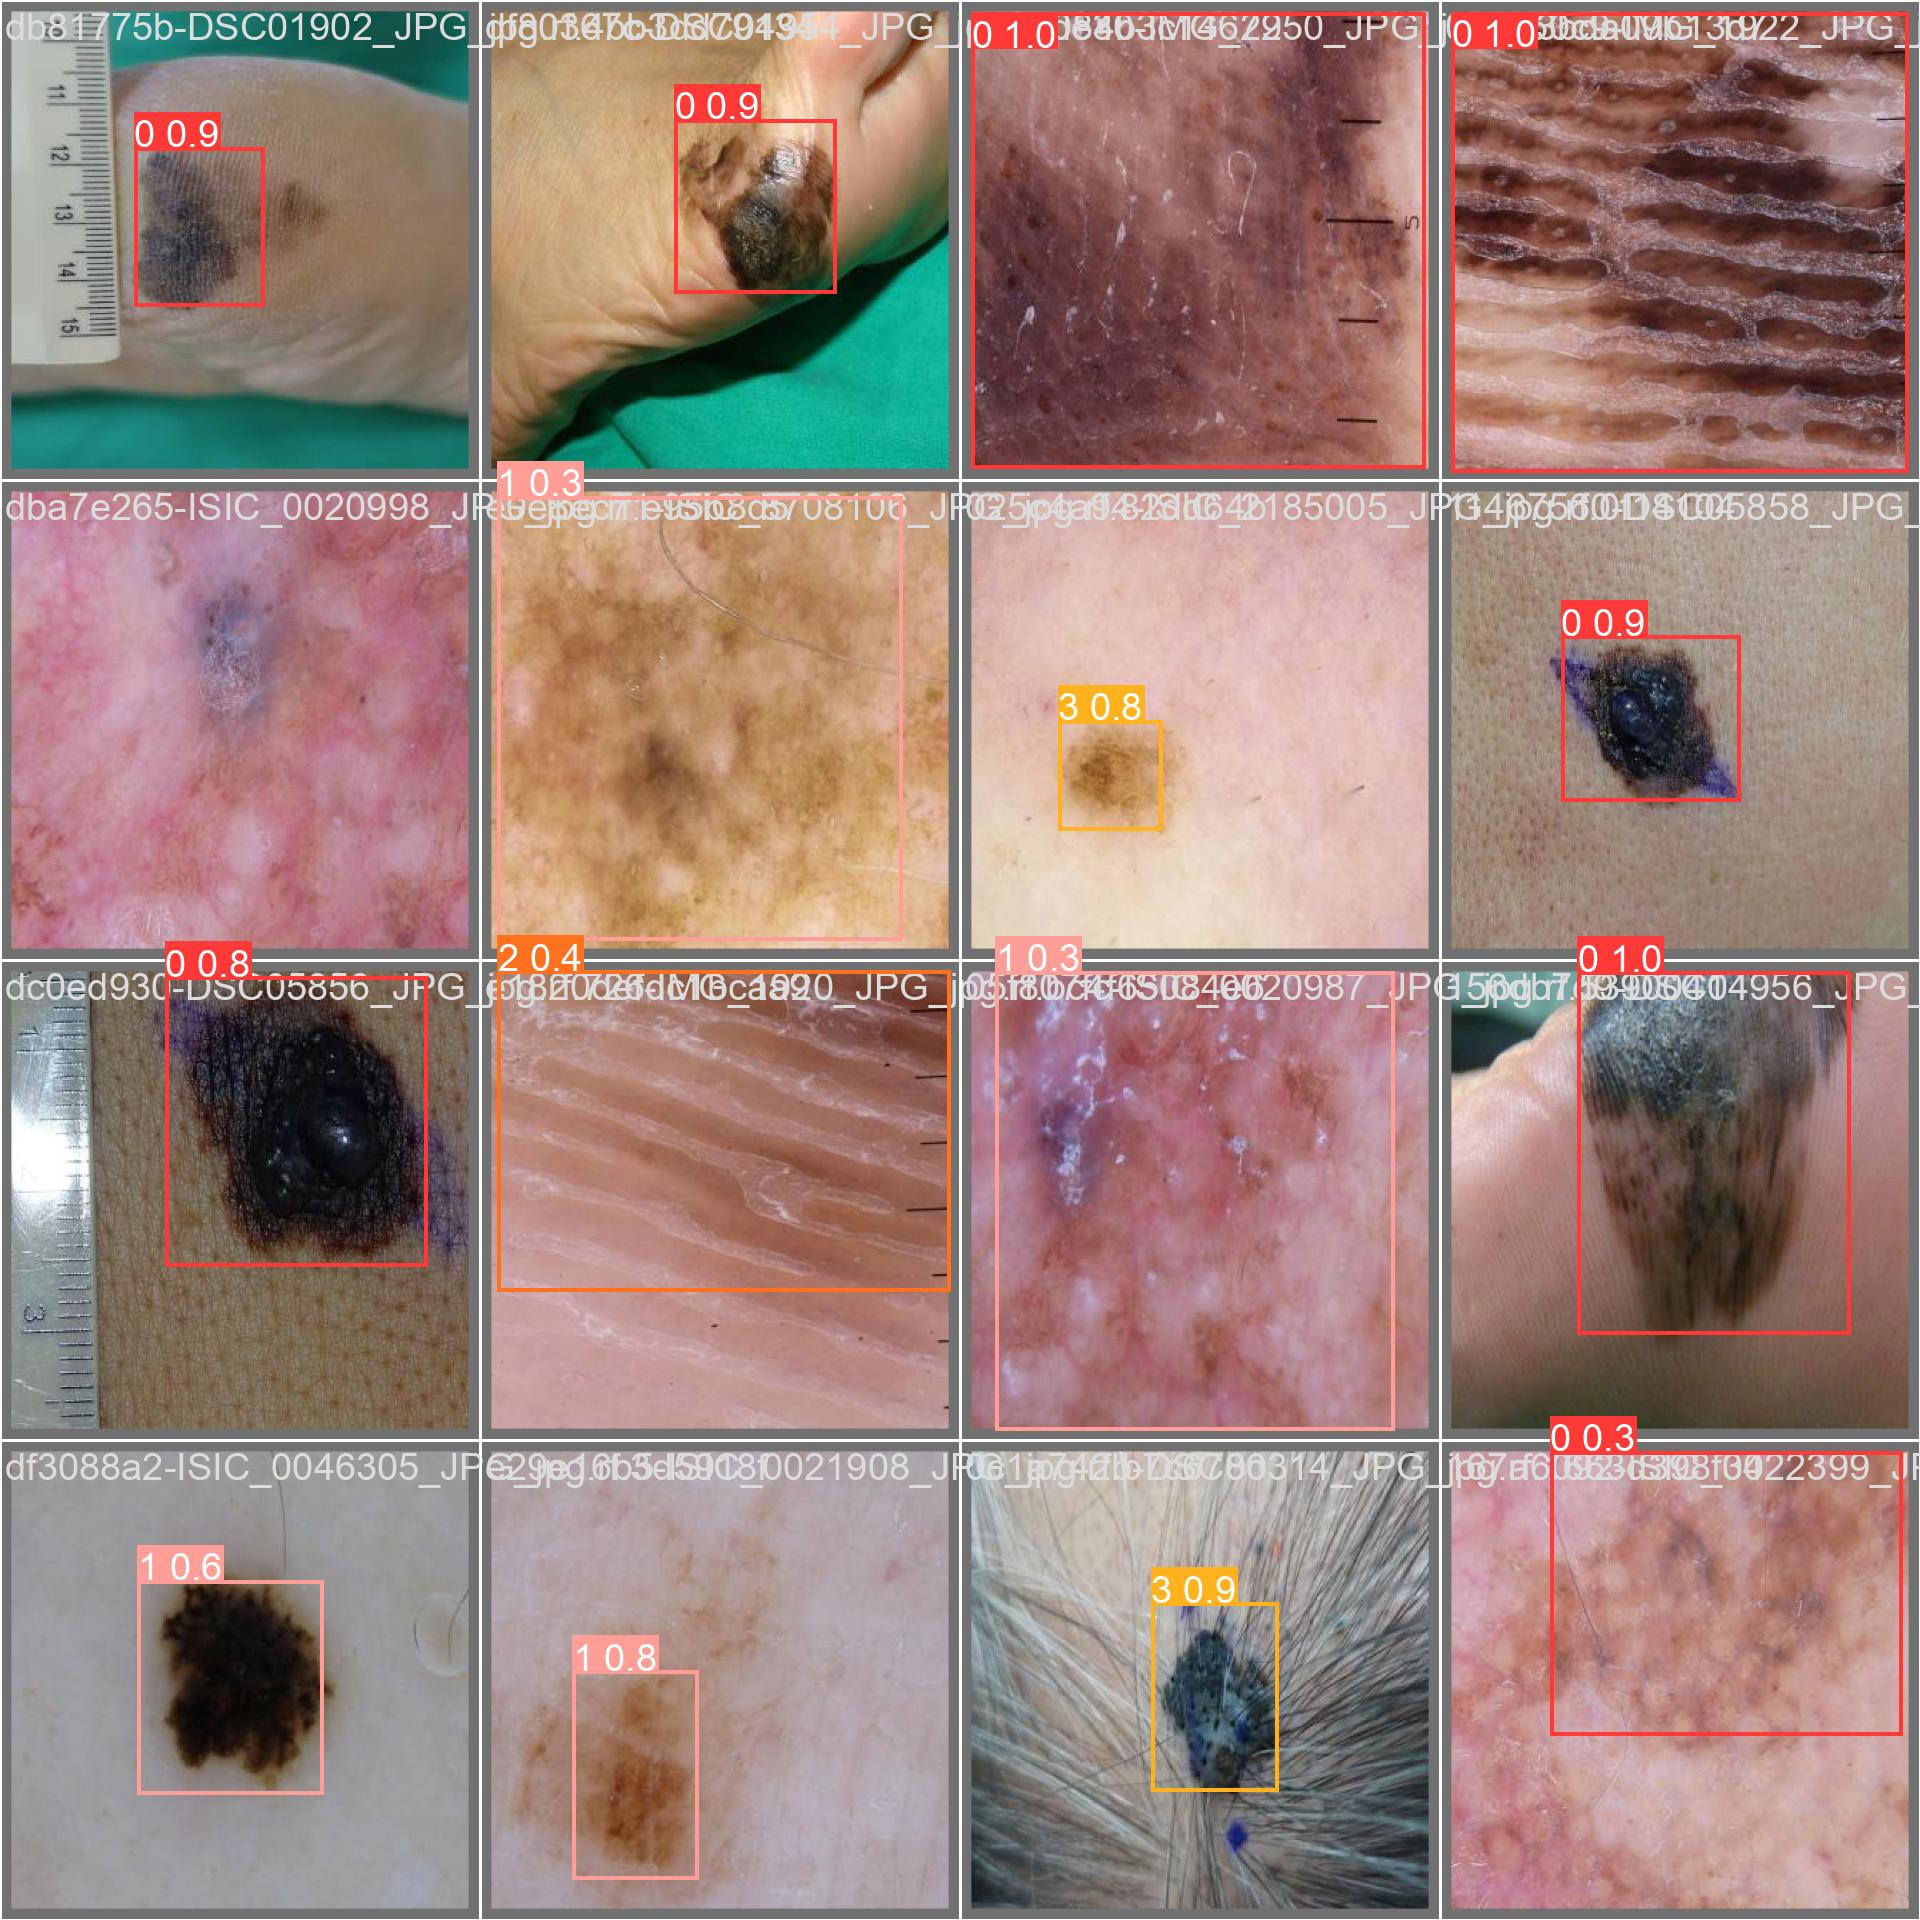

In [18]:

from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/val_batch0_pred.jpg", width=1000)

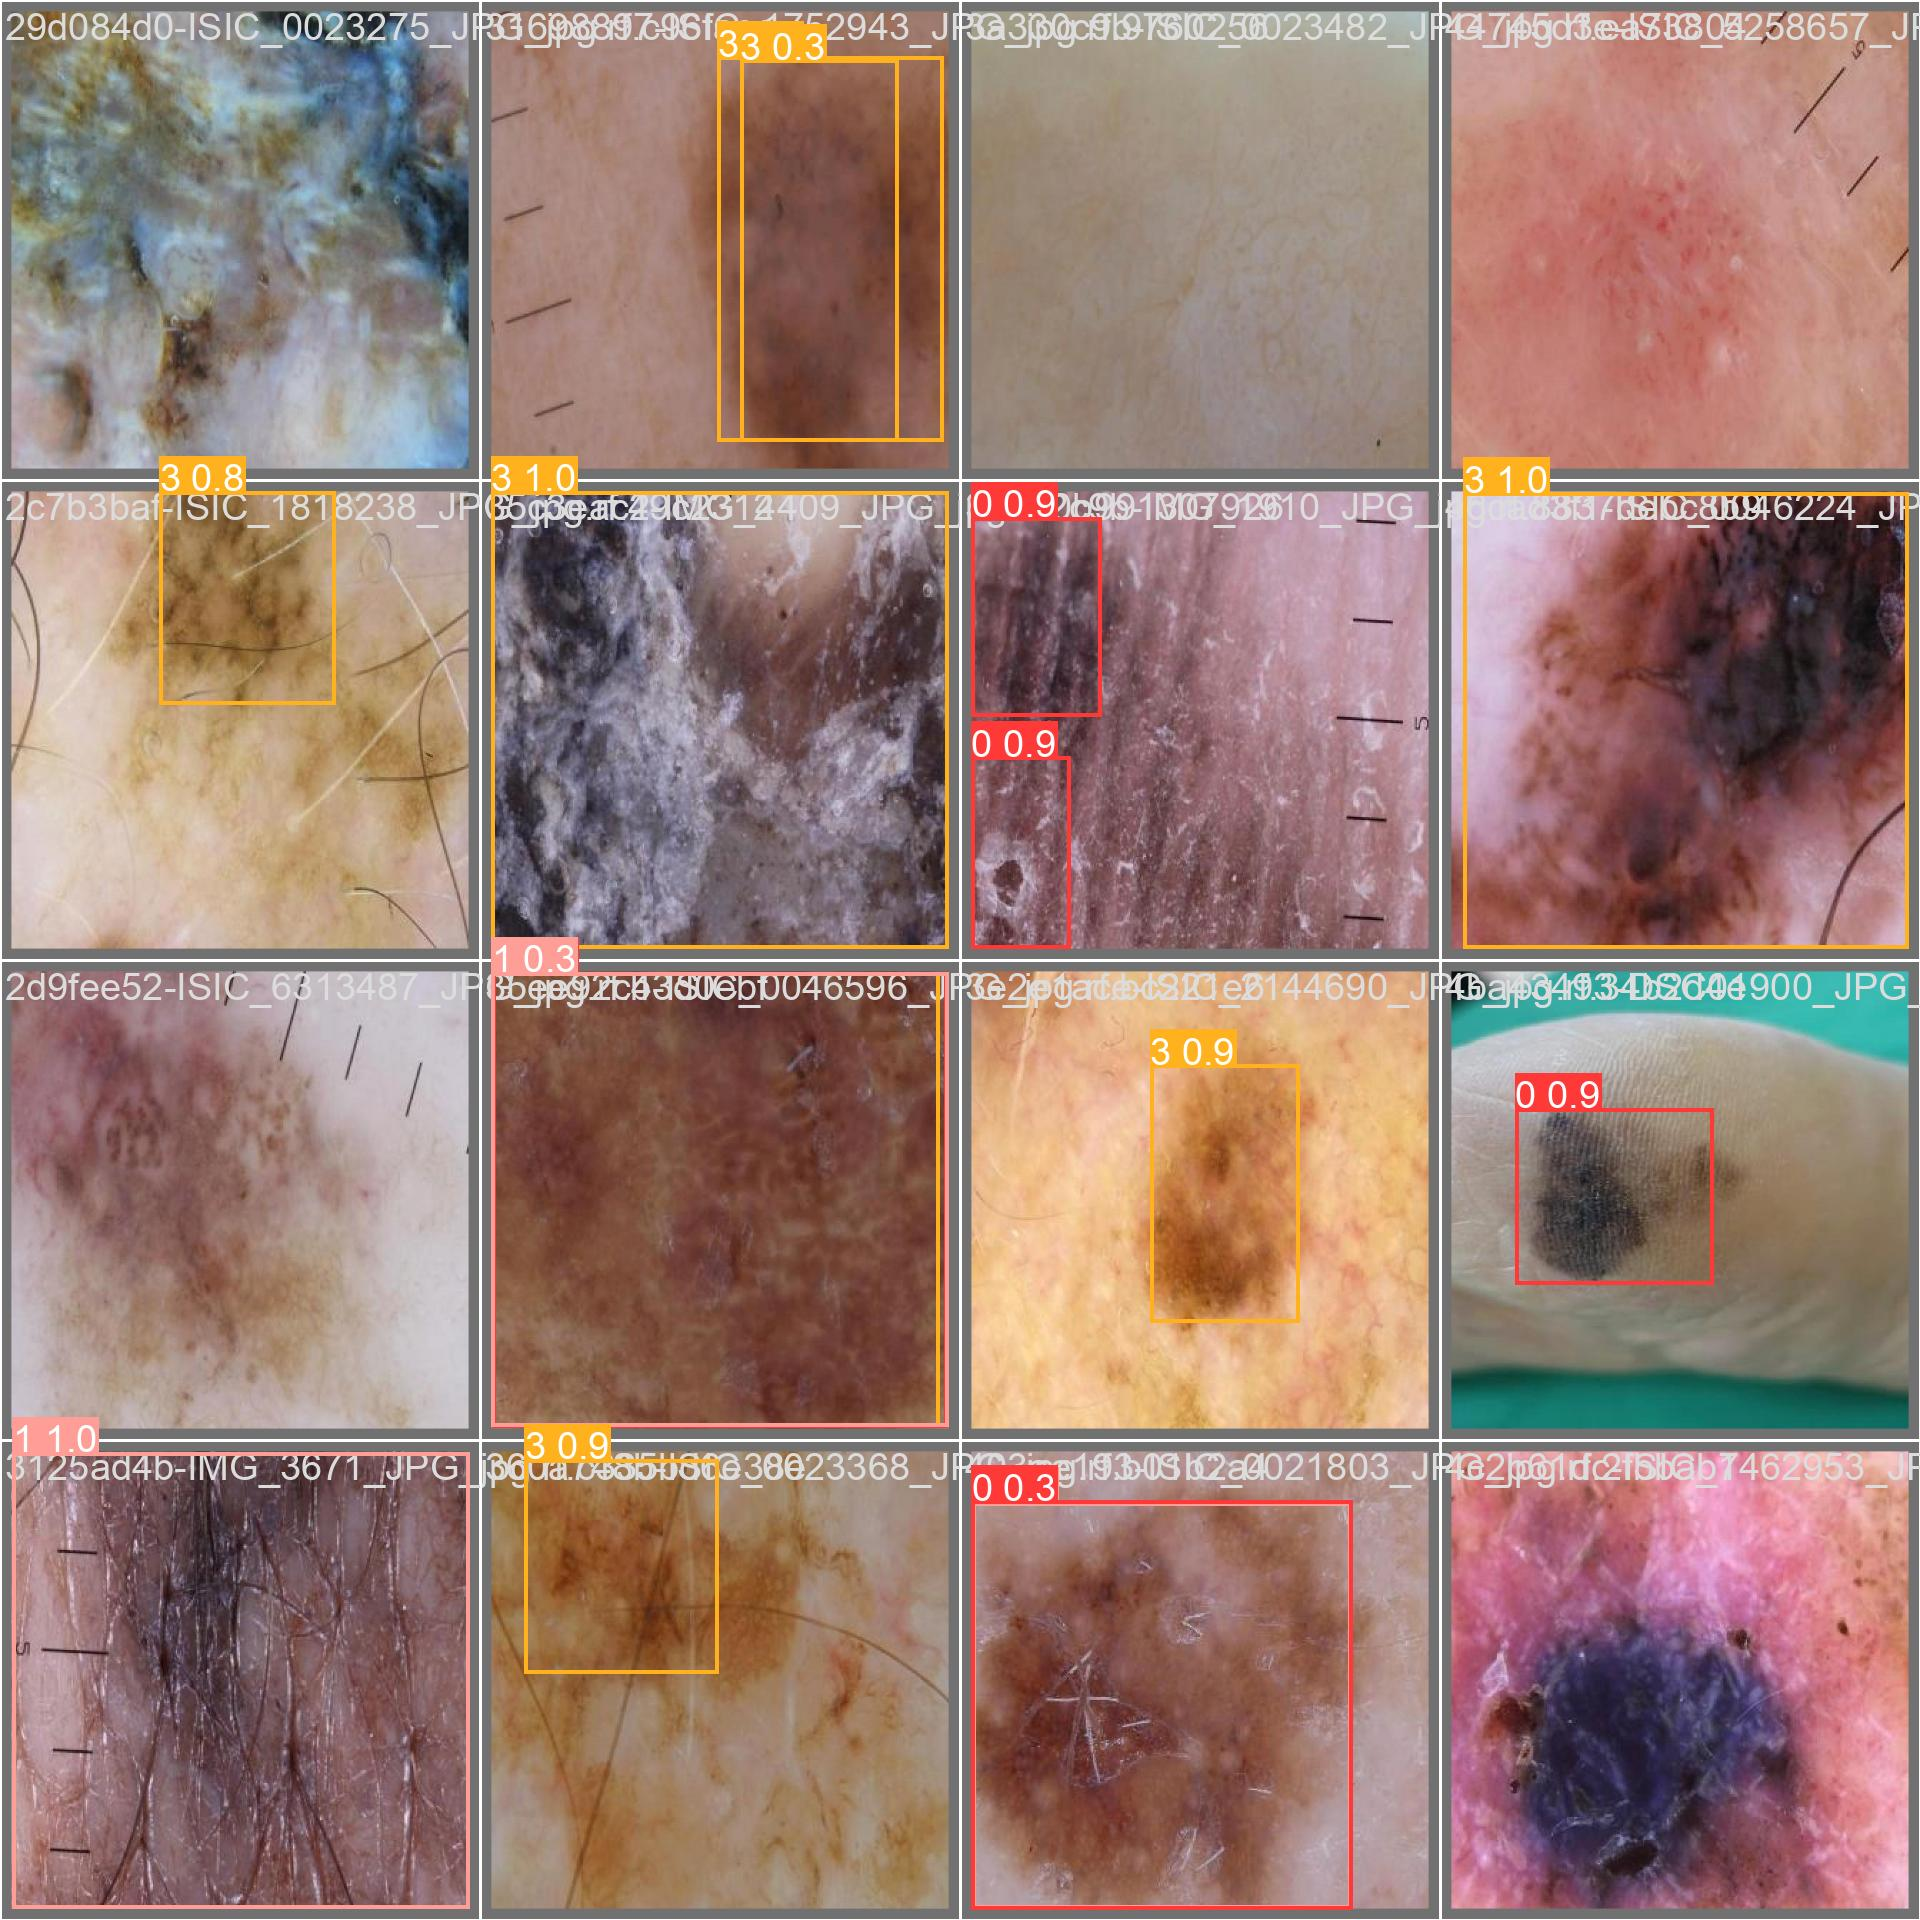

In [19]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/val_batch1_pred.jpg", width=1000)

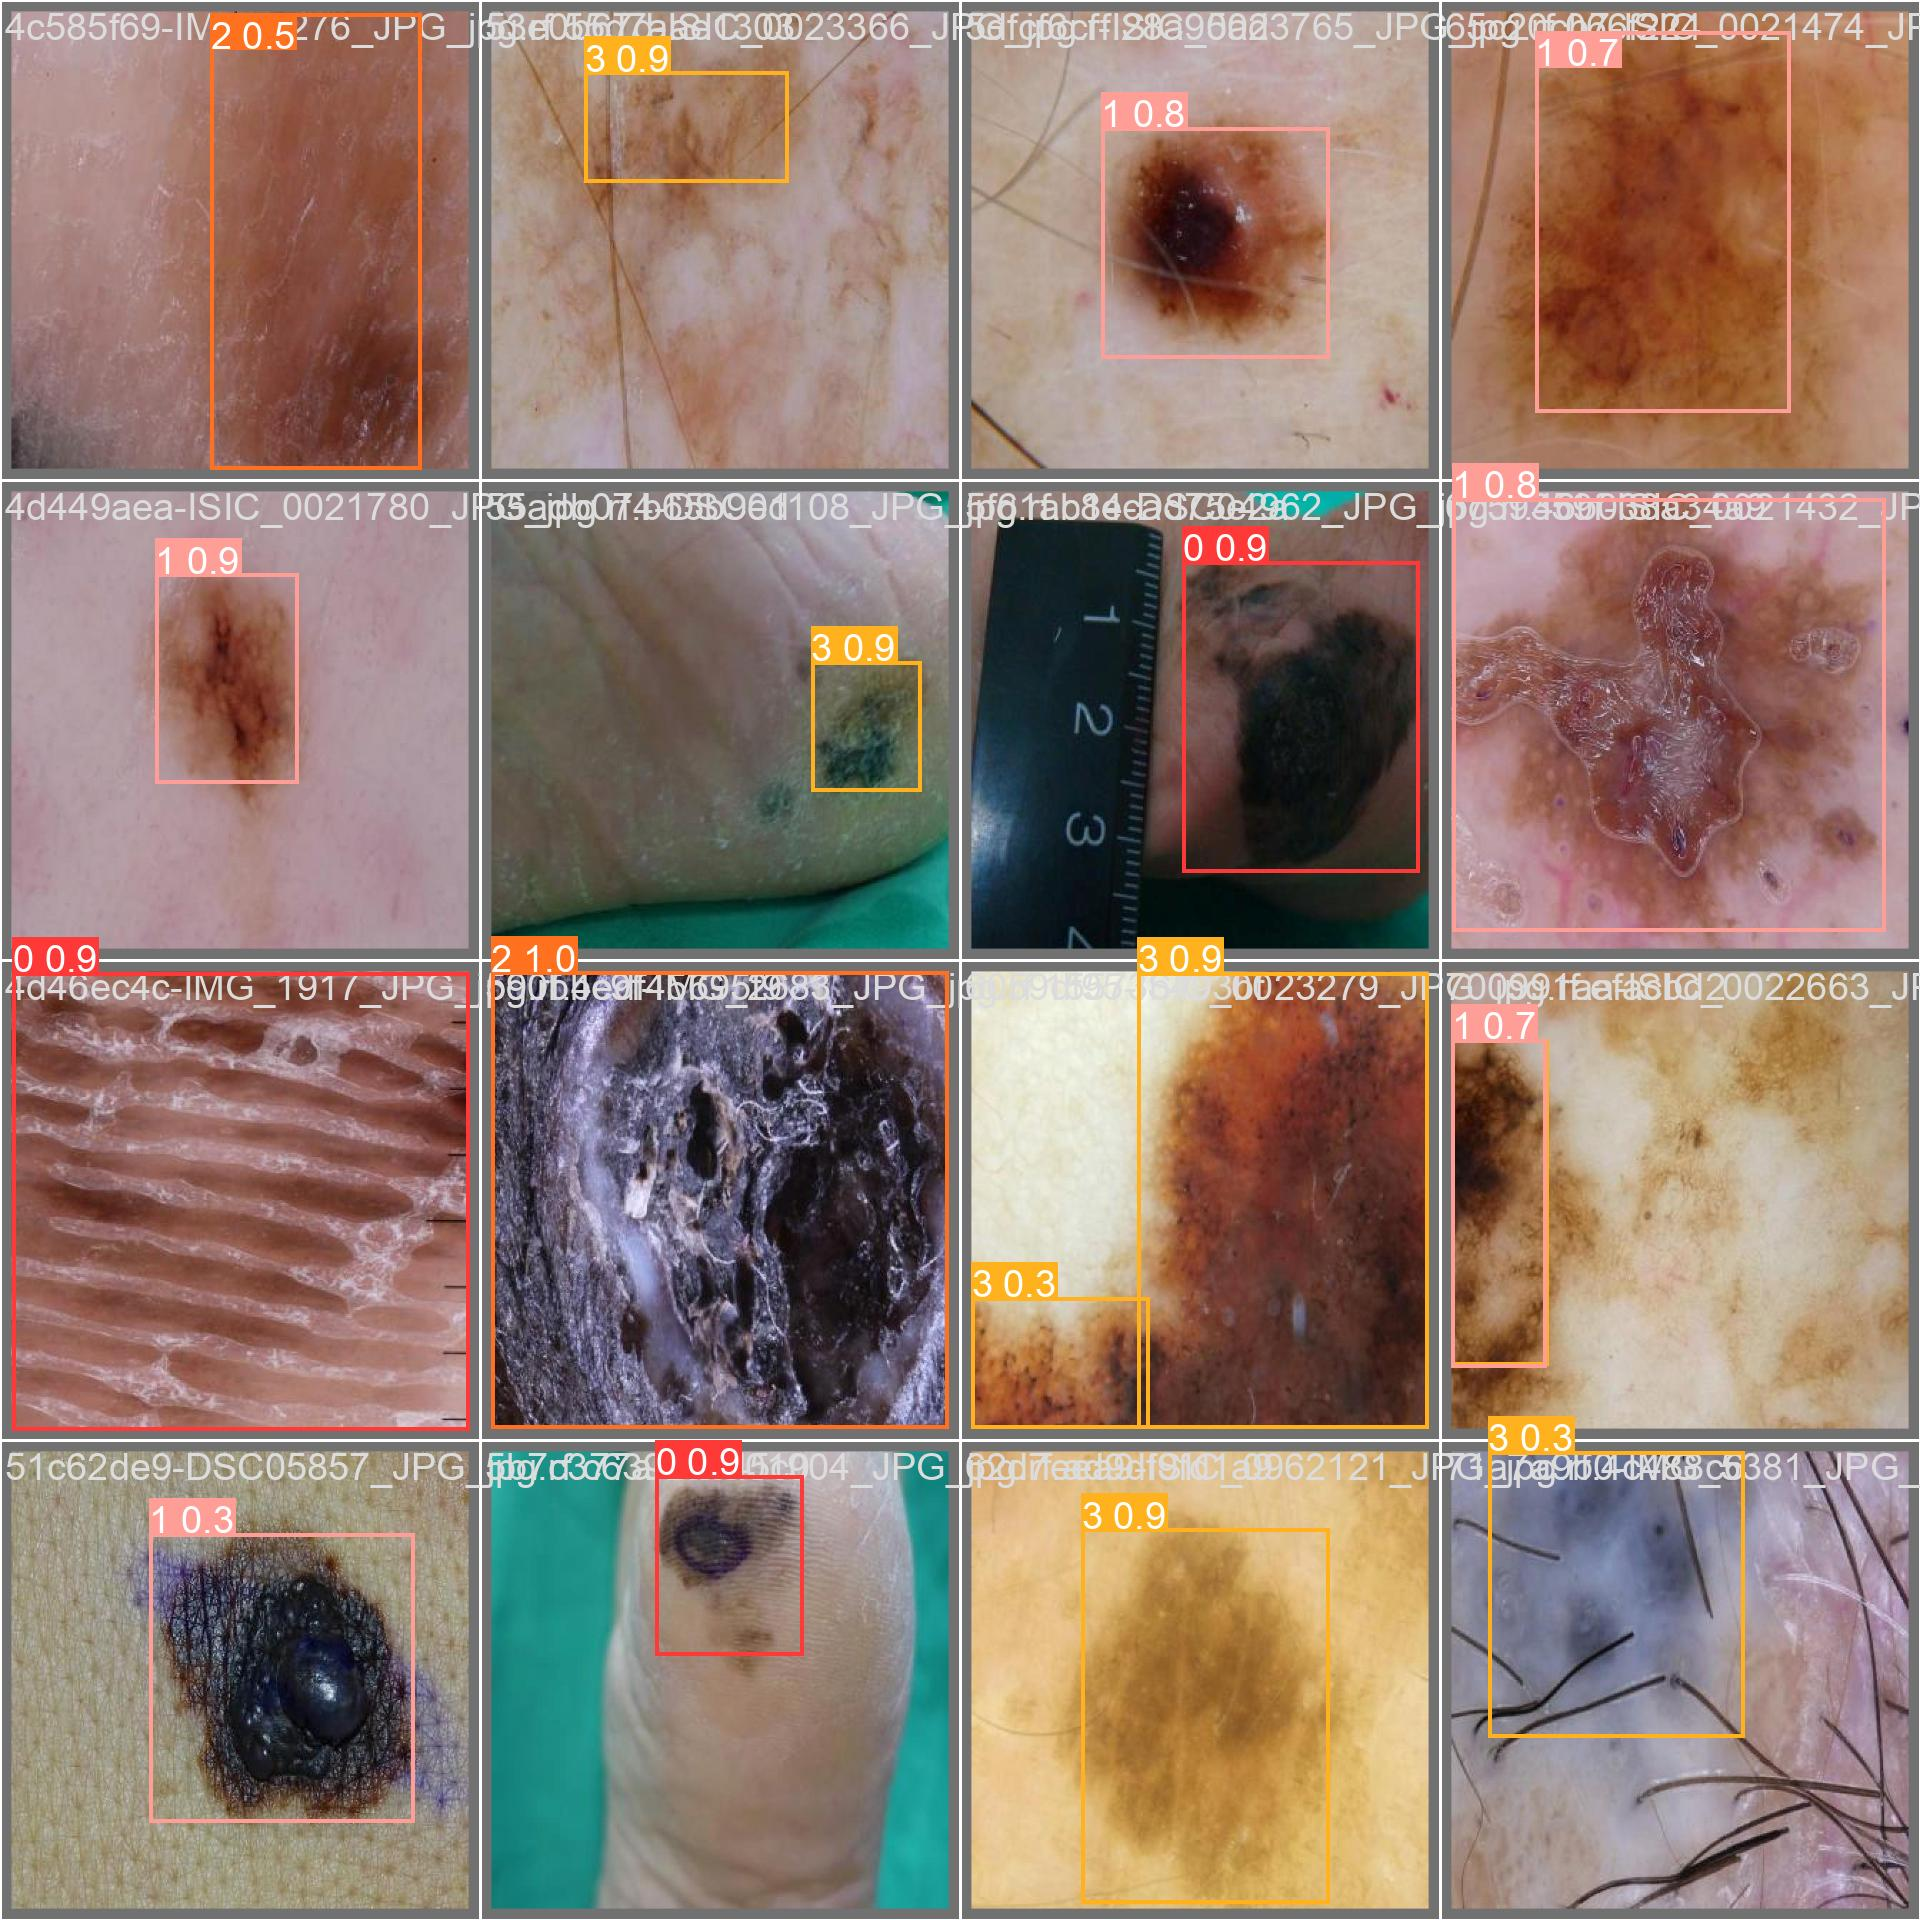

In [20]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/val_batch2_pred.jpg", width=1000)

# Validate Custom Model

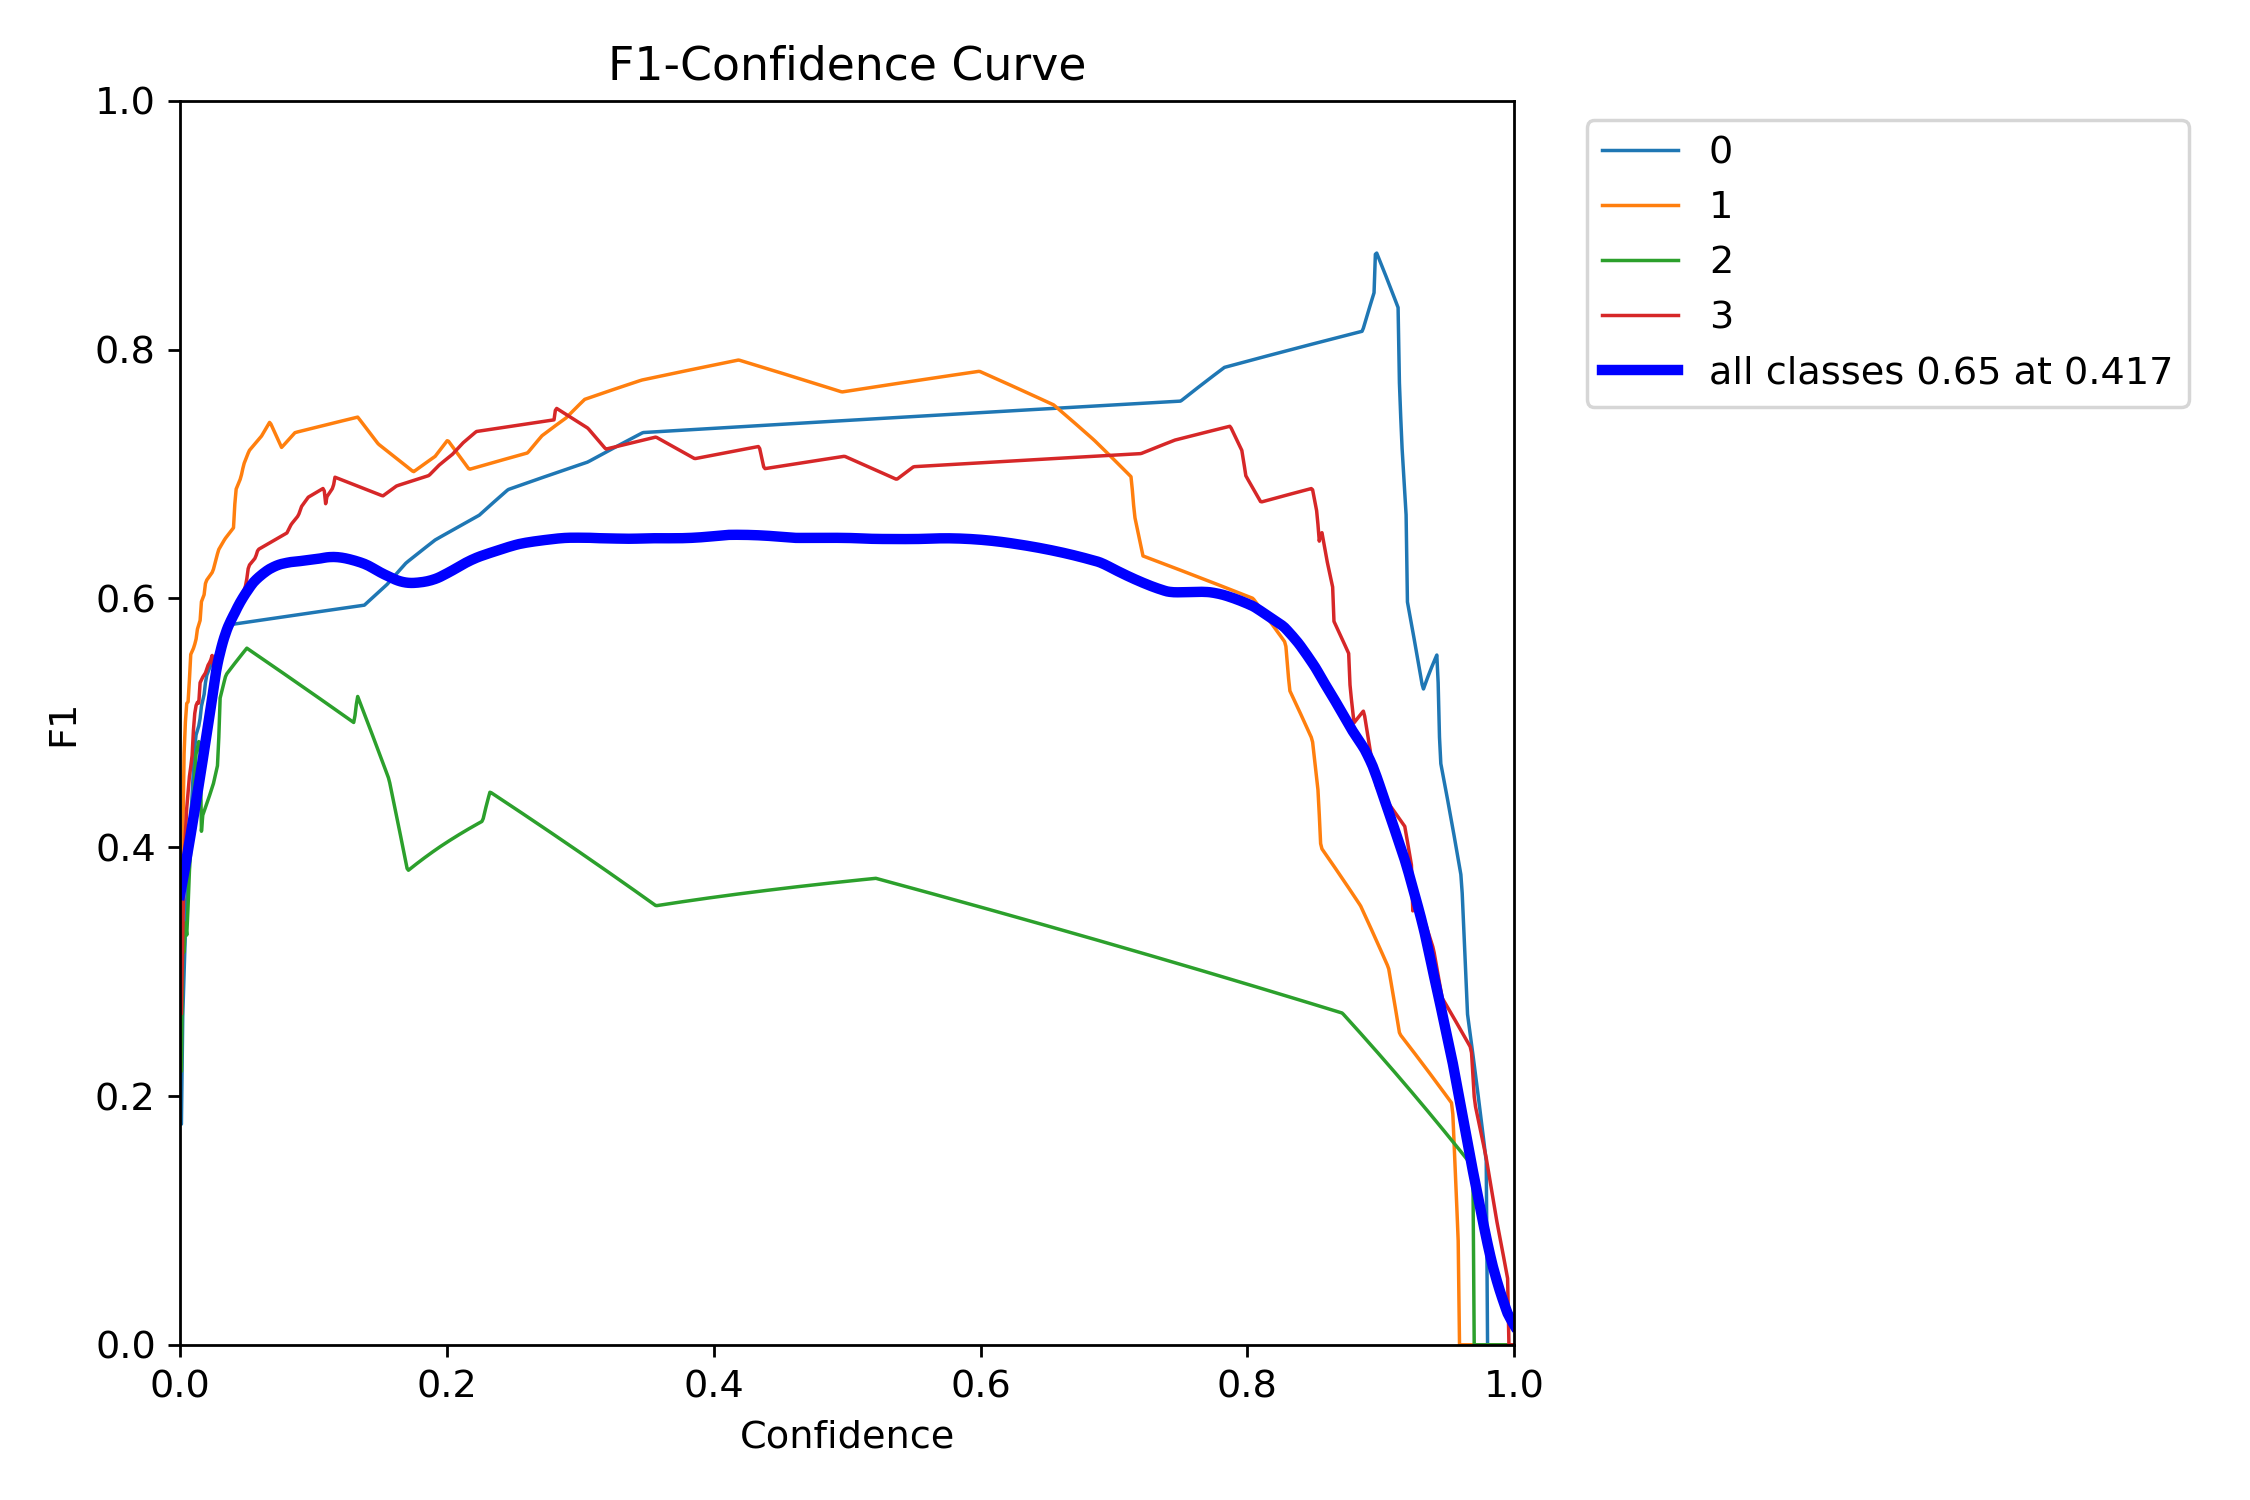

In [21]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/F1_curve.png", width=1000)

In [ ]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/F1_curve.png", width=1000)

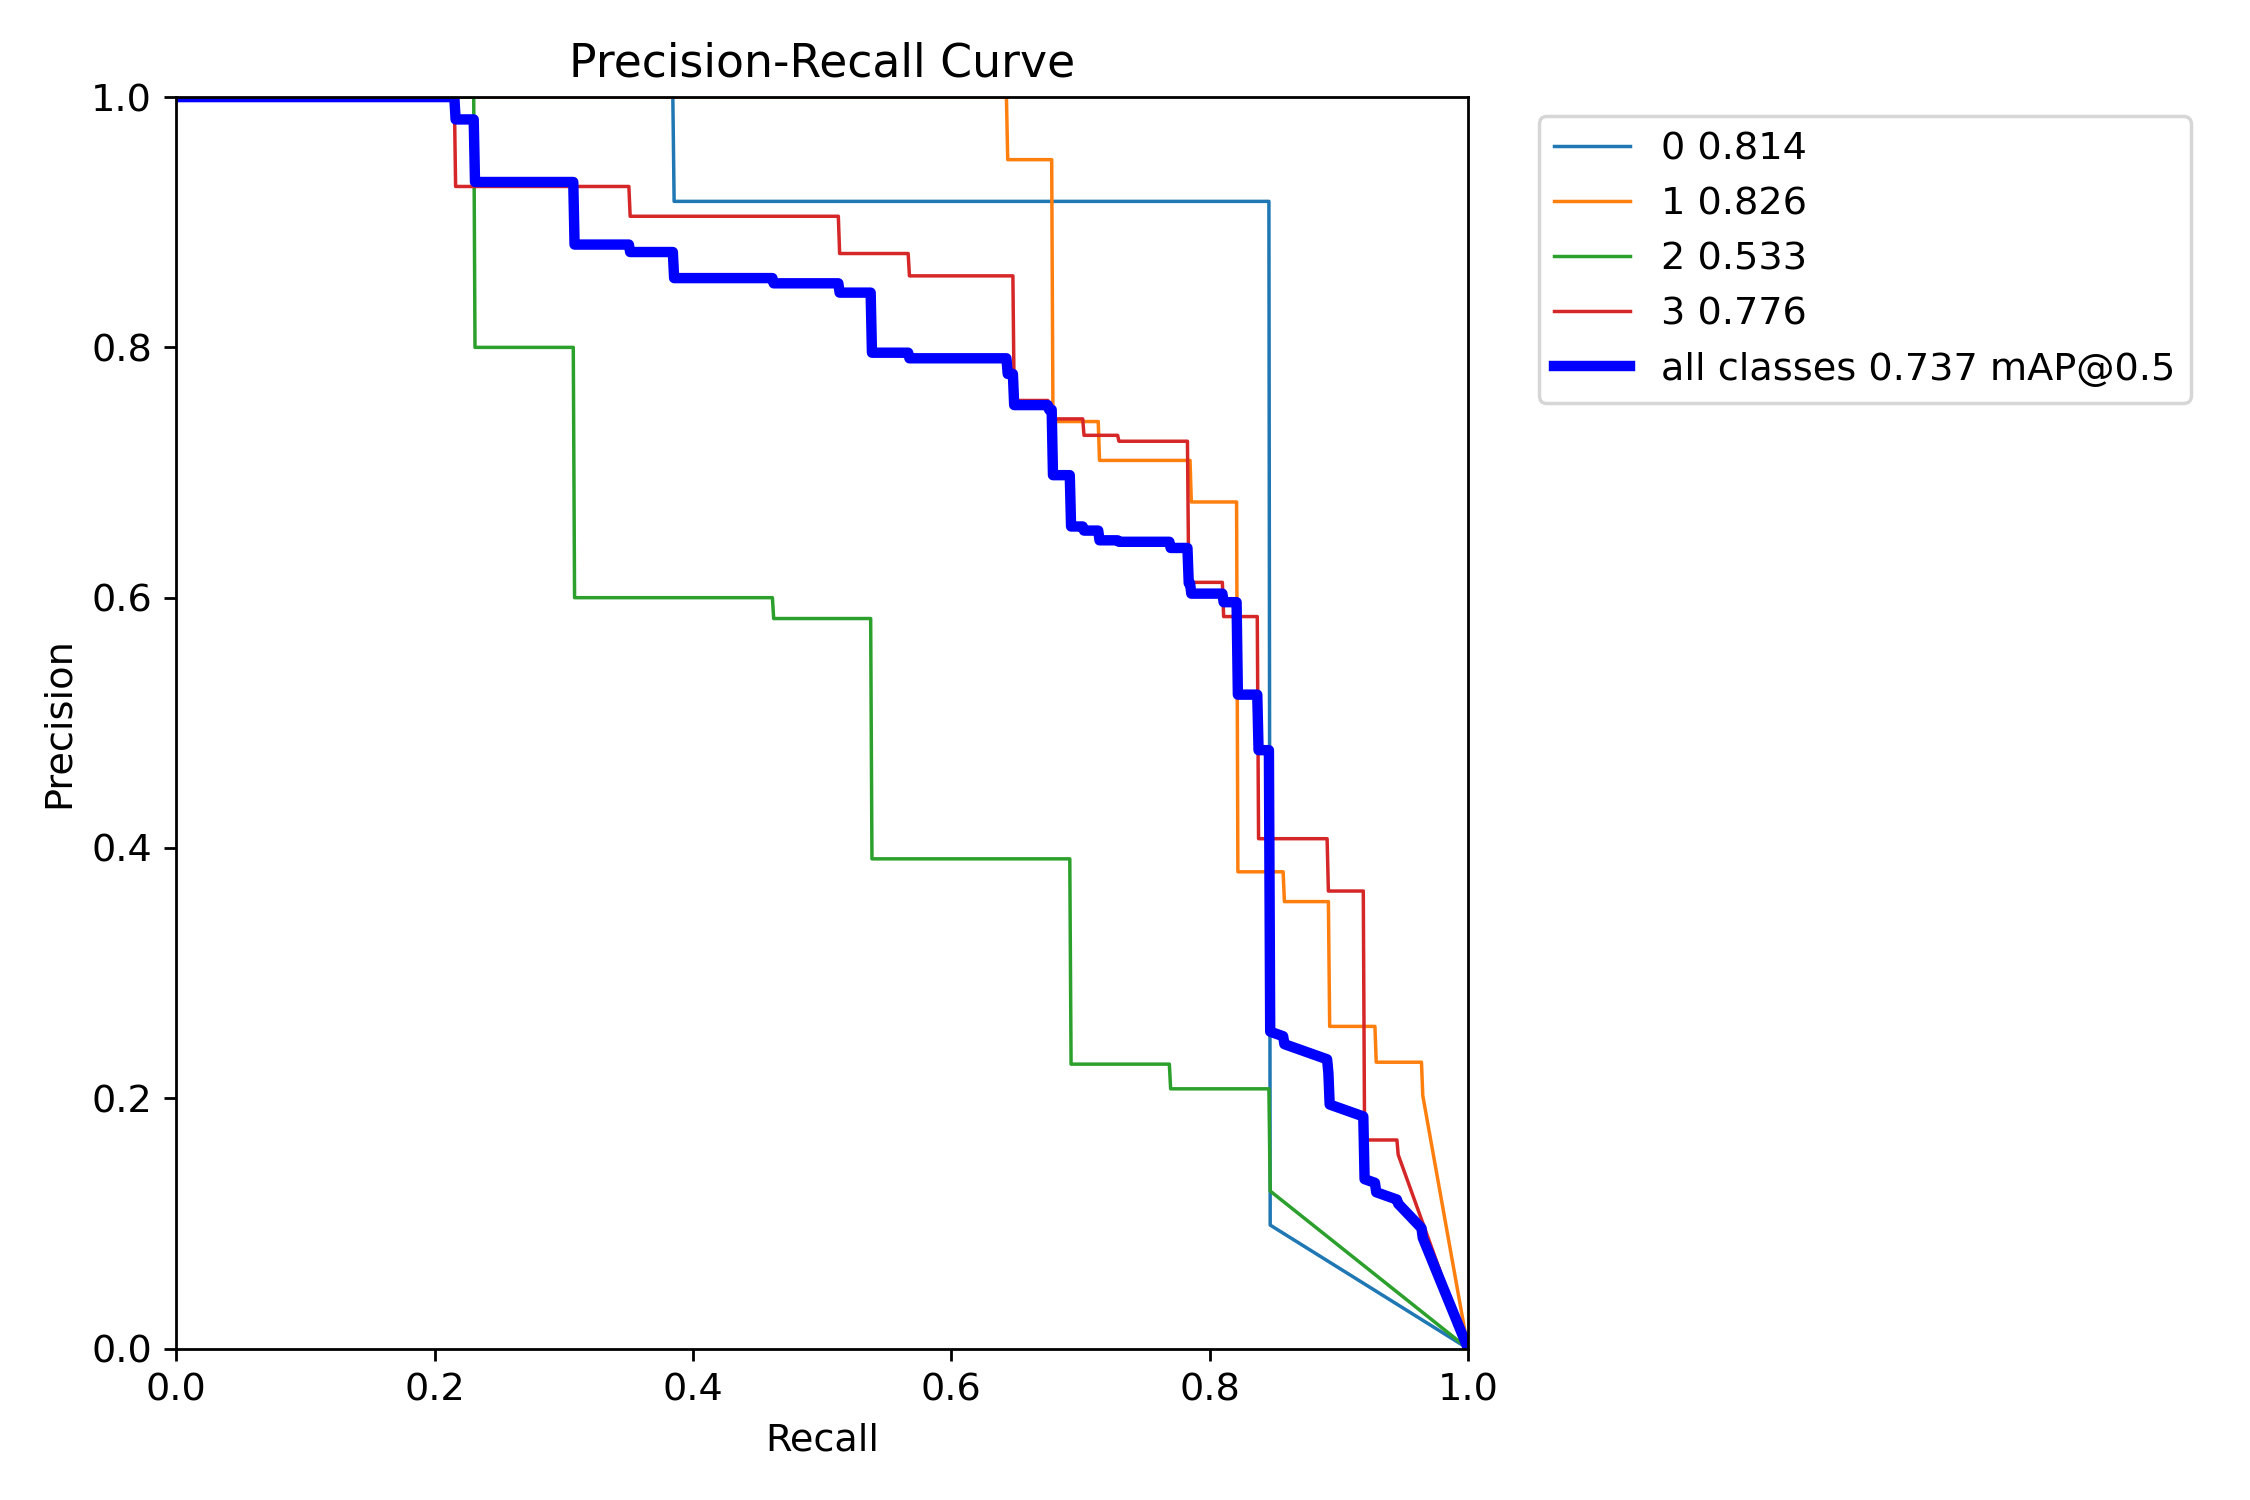

In [23]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/PR_curve.png", width=1000)

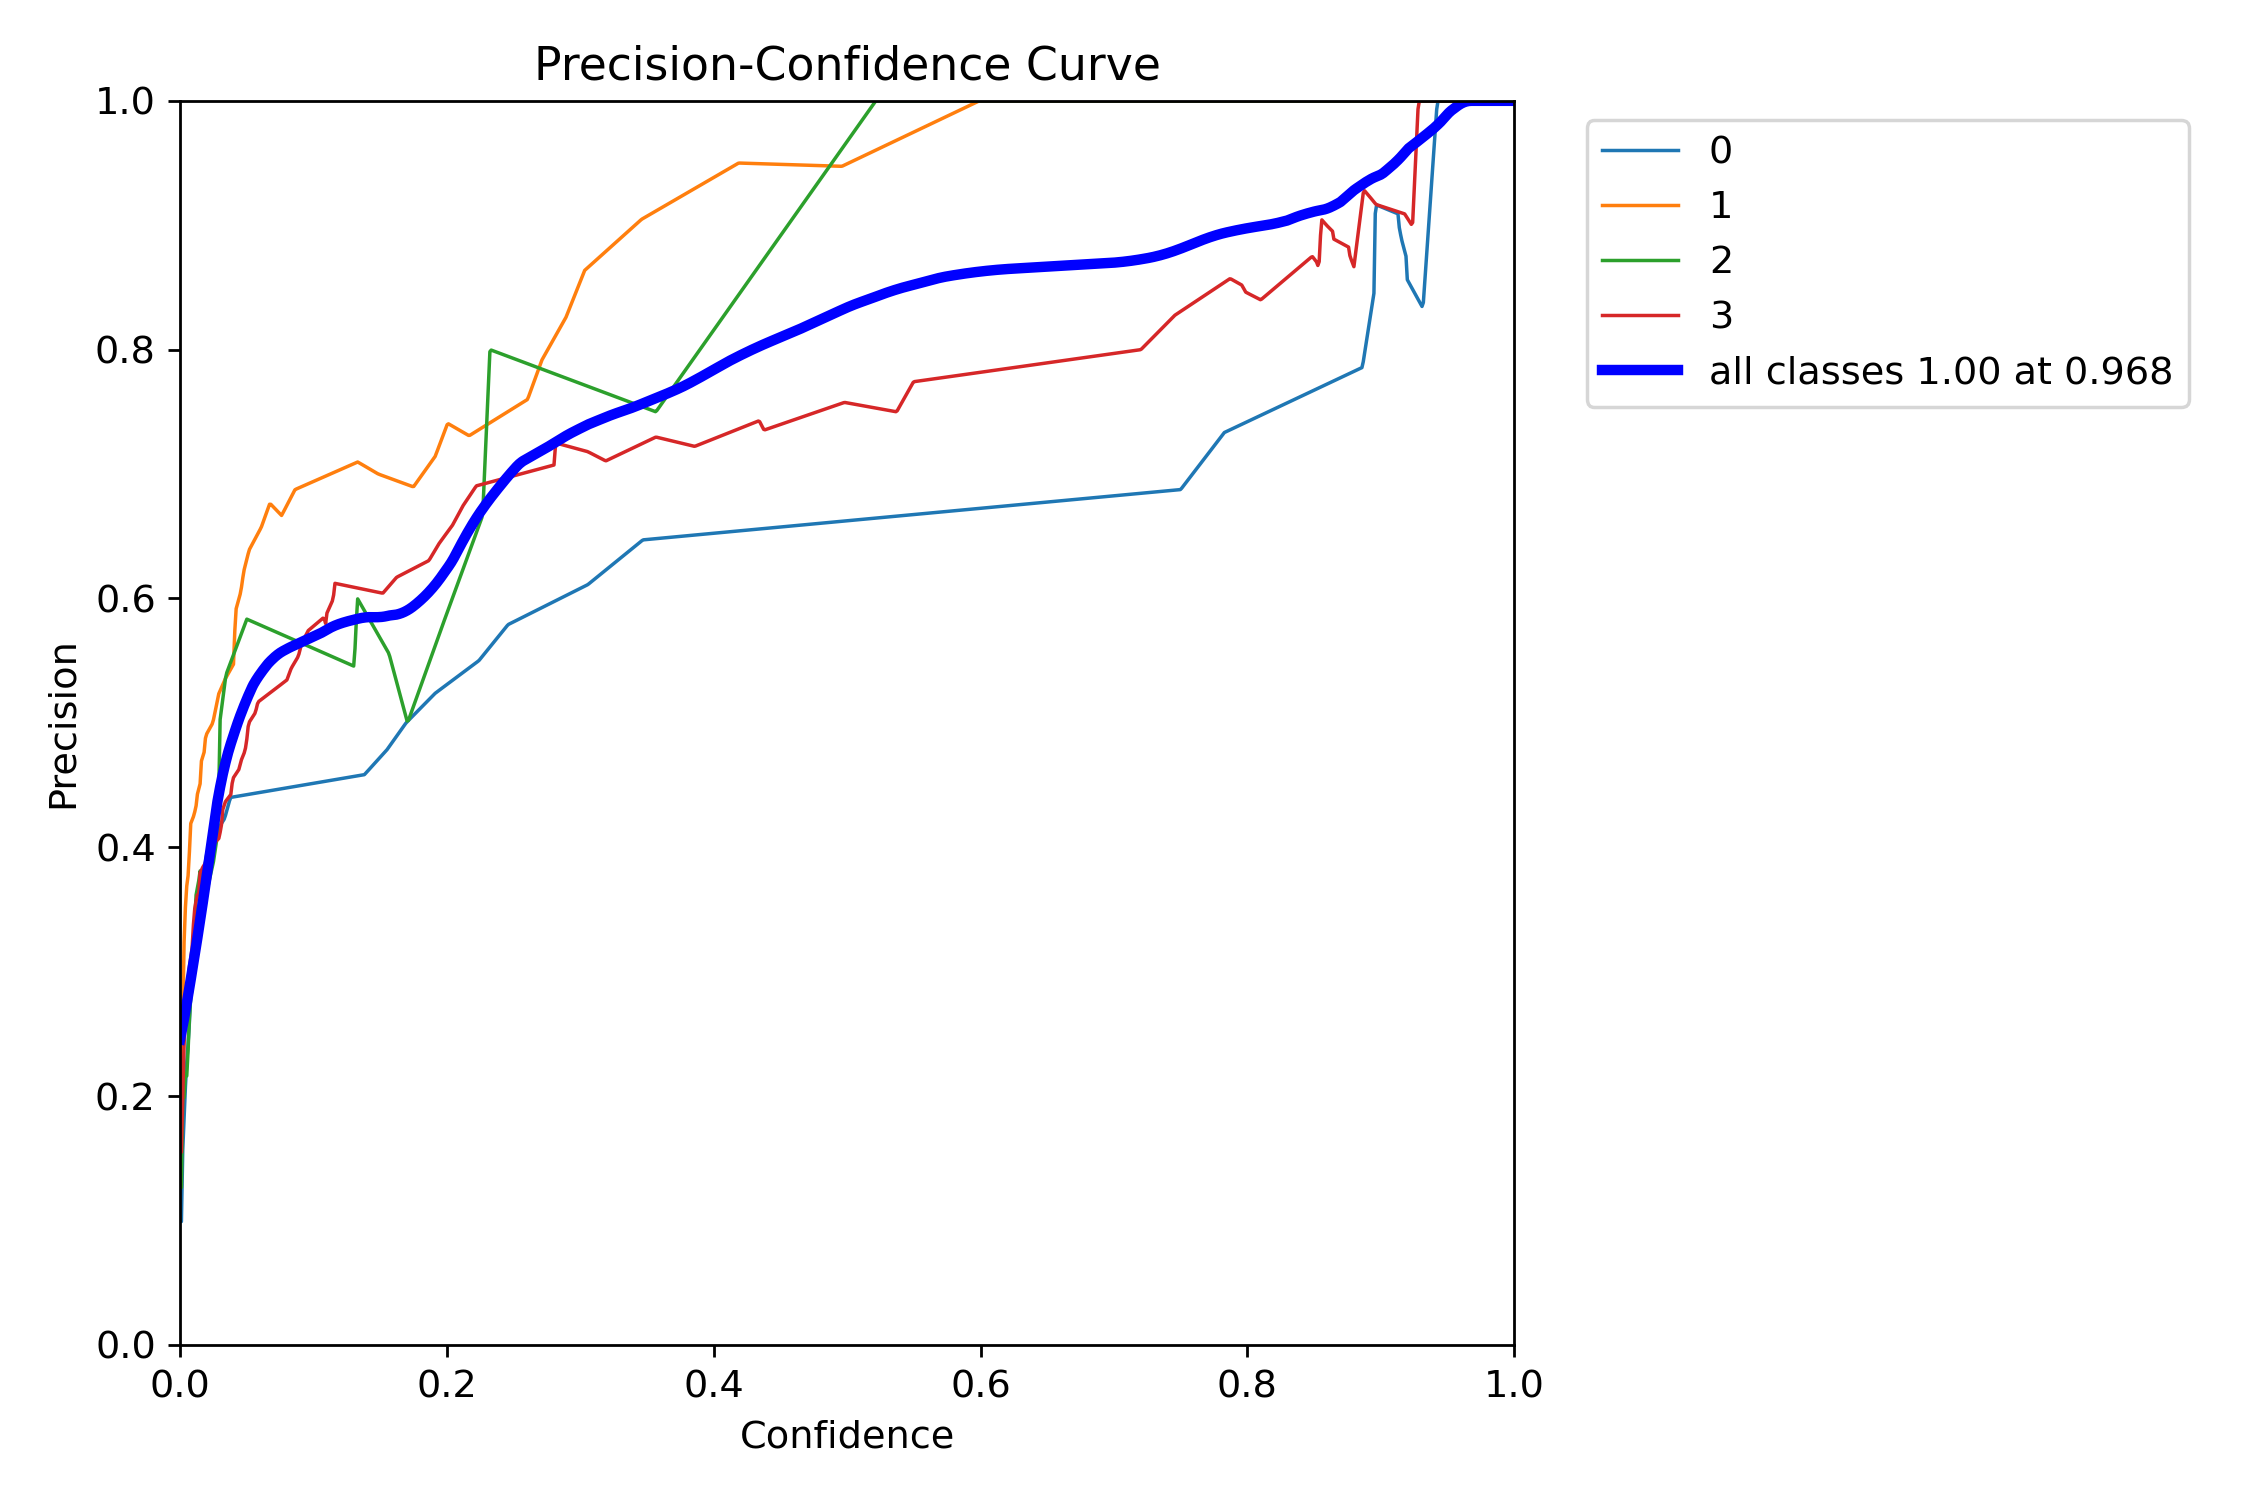

In [24]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/P_curve.png", width=1000)

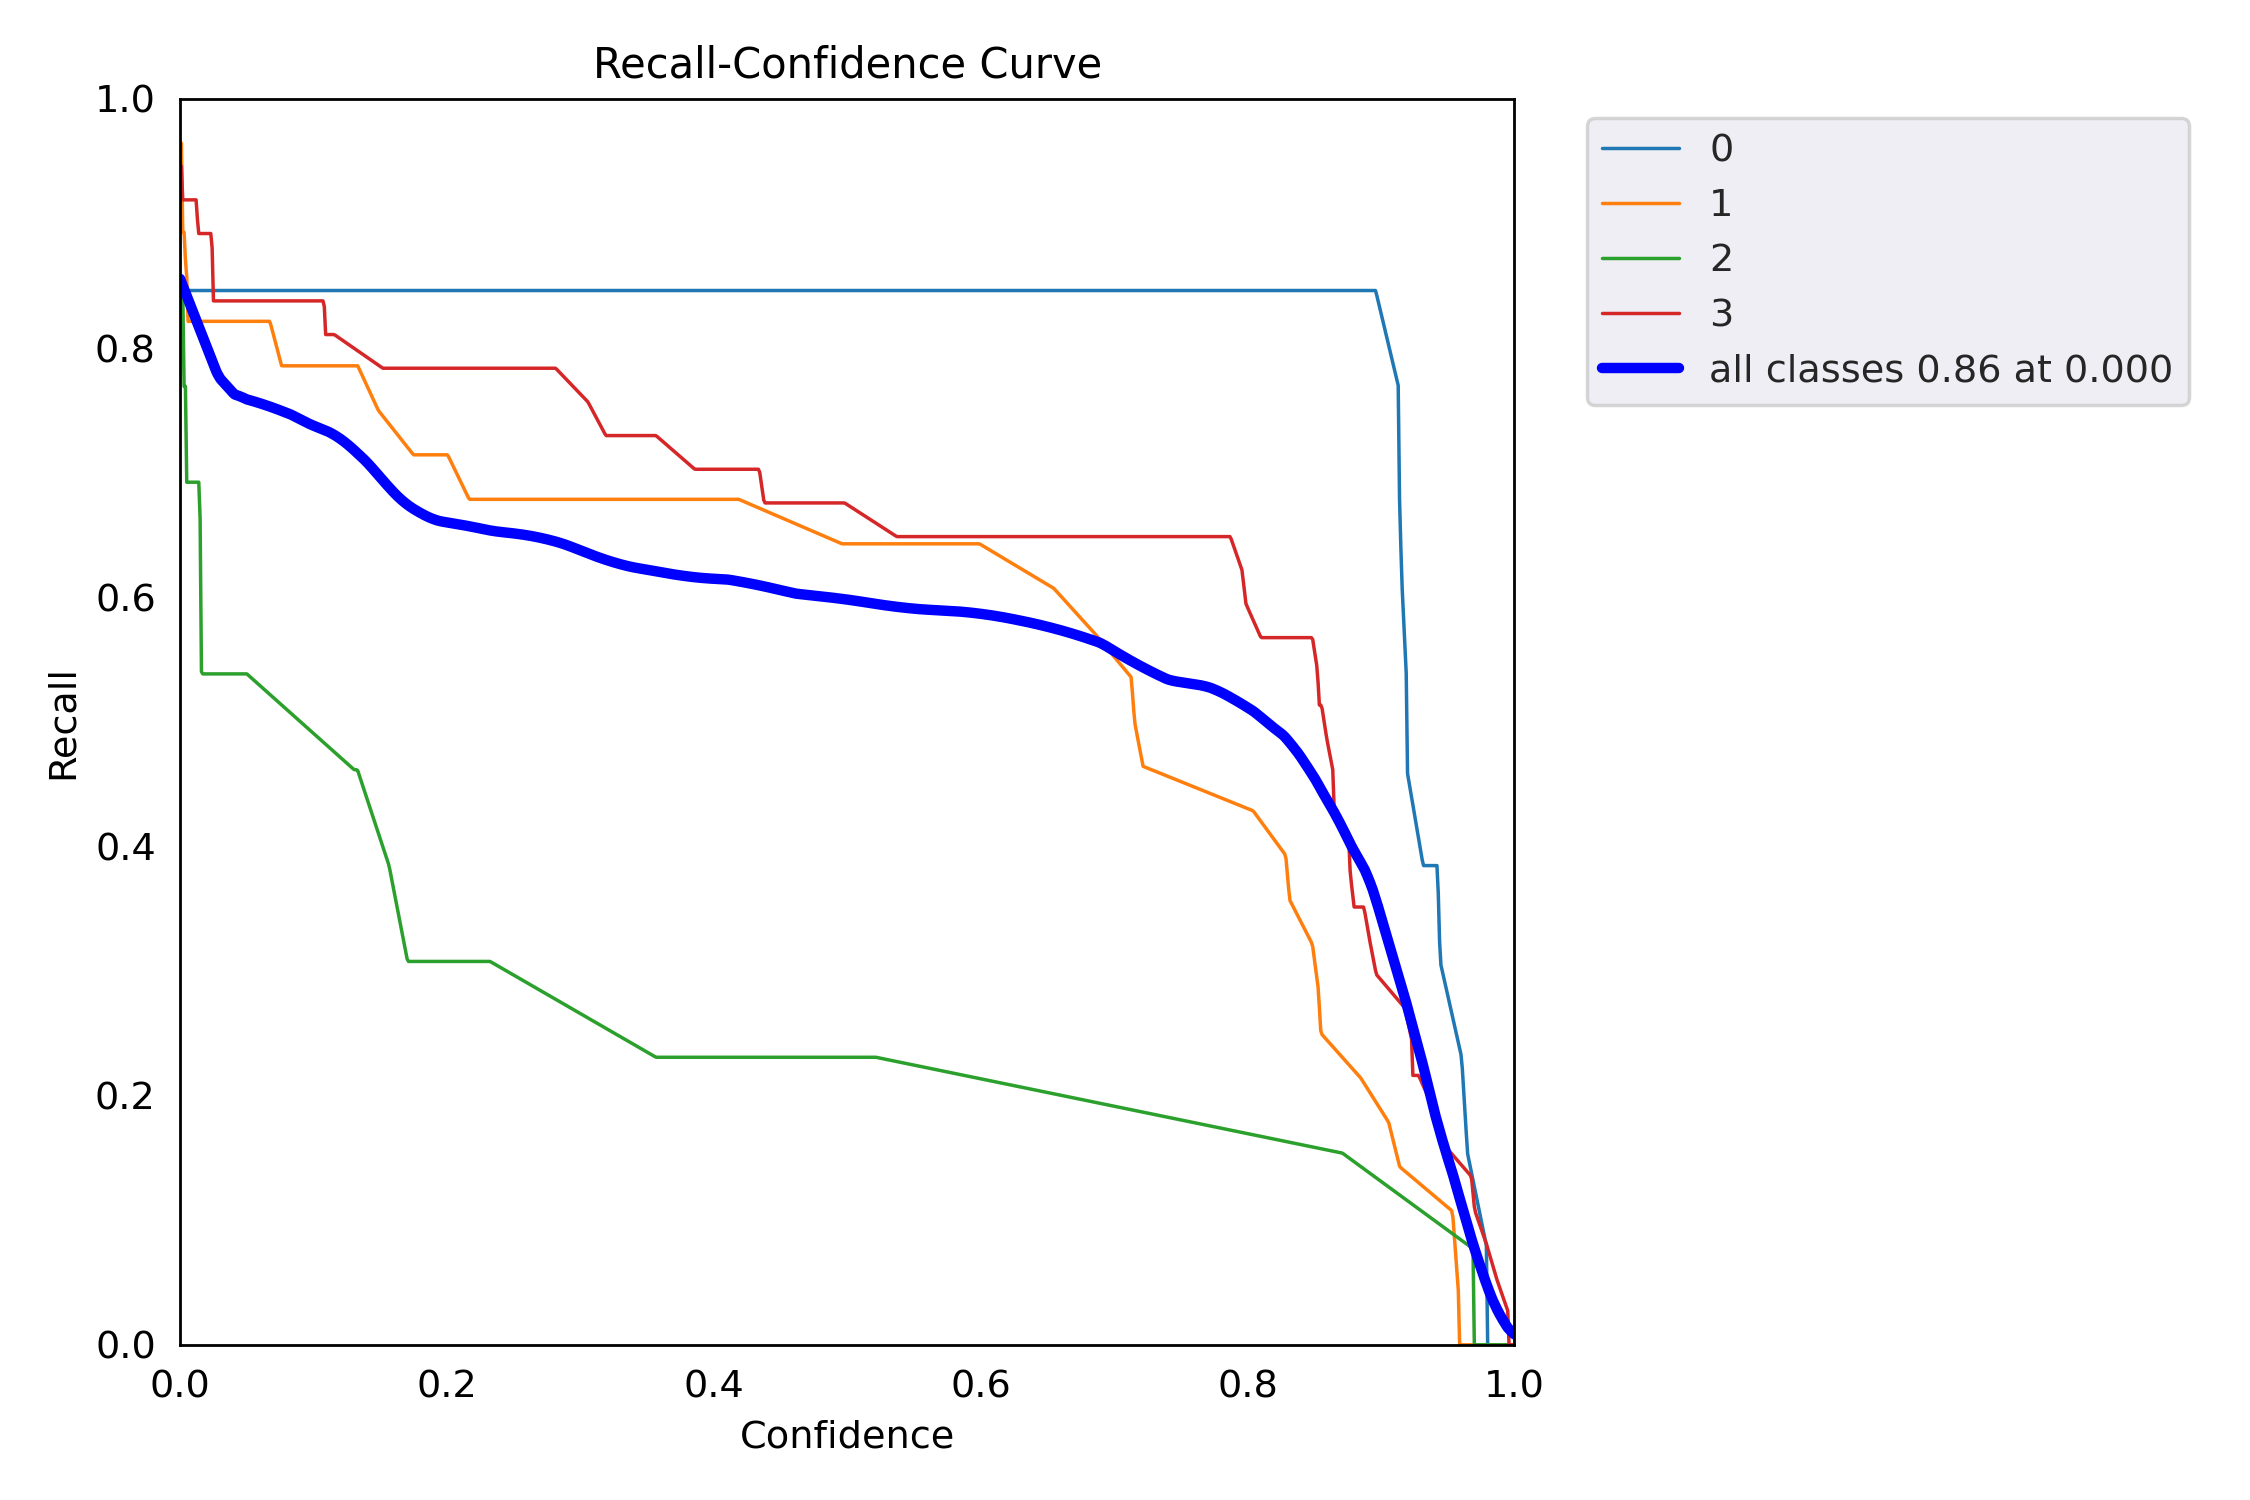

In [25]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/exp/R_curve.png", width=1000)

In [ ]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 16 --conf 0.001 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights {HOME}/yolov9/runs/train/exp/weights/best.pt

In [14]:
# evaluate yolov9 models
!python val_dual.py --data '/content/yolov9/cancer-7/data.yaml' --img 640 --batch 16 --conf 0.001 --iou 0.7 --device 0 --weights '/content/yolov9/runs/train/exp/weights/best.pt'

val_dual: data=/content/yolov9/cancer-7/data.yaml, weights=['/content/yolov9/runs/train/exp/weights/best.pt'], batch_size=16, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)

Fusing layers... 
yolov9-e summary: 1119 layers, 69352952 parameters, 0 gradients, 243.3 GFLOPs
val: Scanning /content/yolov9/cancer-7/valid/labels.cache... 91 images, 2 backgrounds, 0 corrupt: 100% 91/91 [00:00<?, ?it/s]
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
                 Class     Images  Instances          P  

In [41]:
# inference yolov9 models
!python detect.py --source '/content/yolov9/cancer-7/test/images/00c7b7c5-DSC01908_JPG_jpg.rf.585f8f617faecc7ca2201d9e4d423db0.jpg' --img 640 --device 0 --weights '/content/yolov9/runs/train/exp/weights/best.pt' --name detect

detect: weights=['/content/yolov9/runs/train/exp/weights/best.pt'], source=/content/yolov9/cancer-7/test/images/00c7b7c5-DSC01908_JPG_jpg.rf.585f8f617faecc7ca2201d9e4d423db0.jpg, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=detect, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)

Fusing layers... 
yolov9-e summary: 1119 layers, 69352952 parameters, 0 gradients, 243.3 GFLOPs
image 1/1 /content/yolov9/cancer-7/test/images/00c7b7c5-DSC01908_JPG_jpg.rf.585f8f617faecc7ca2201d9e4d423db0.jpg: 640x640 (no detections), 102.8ms
Speed: 0.5ms pre-process, 102.8ms inference, 22.5ms NMS per image at shape (1, 3, 640, 640)
Results 

## validation results

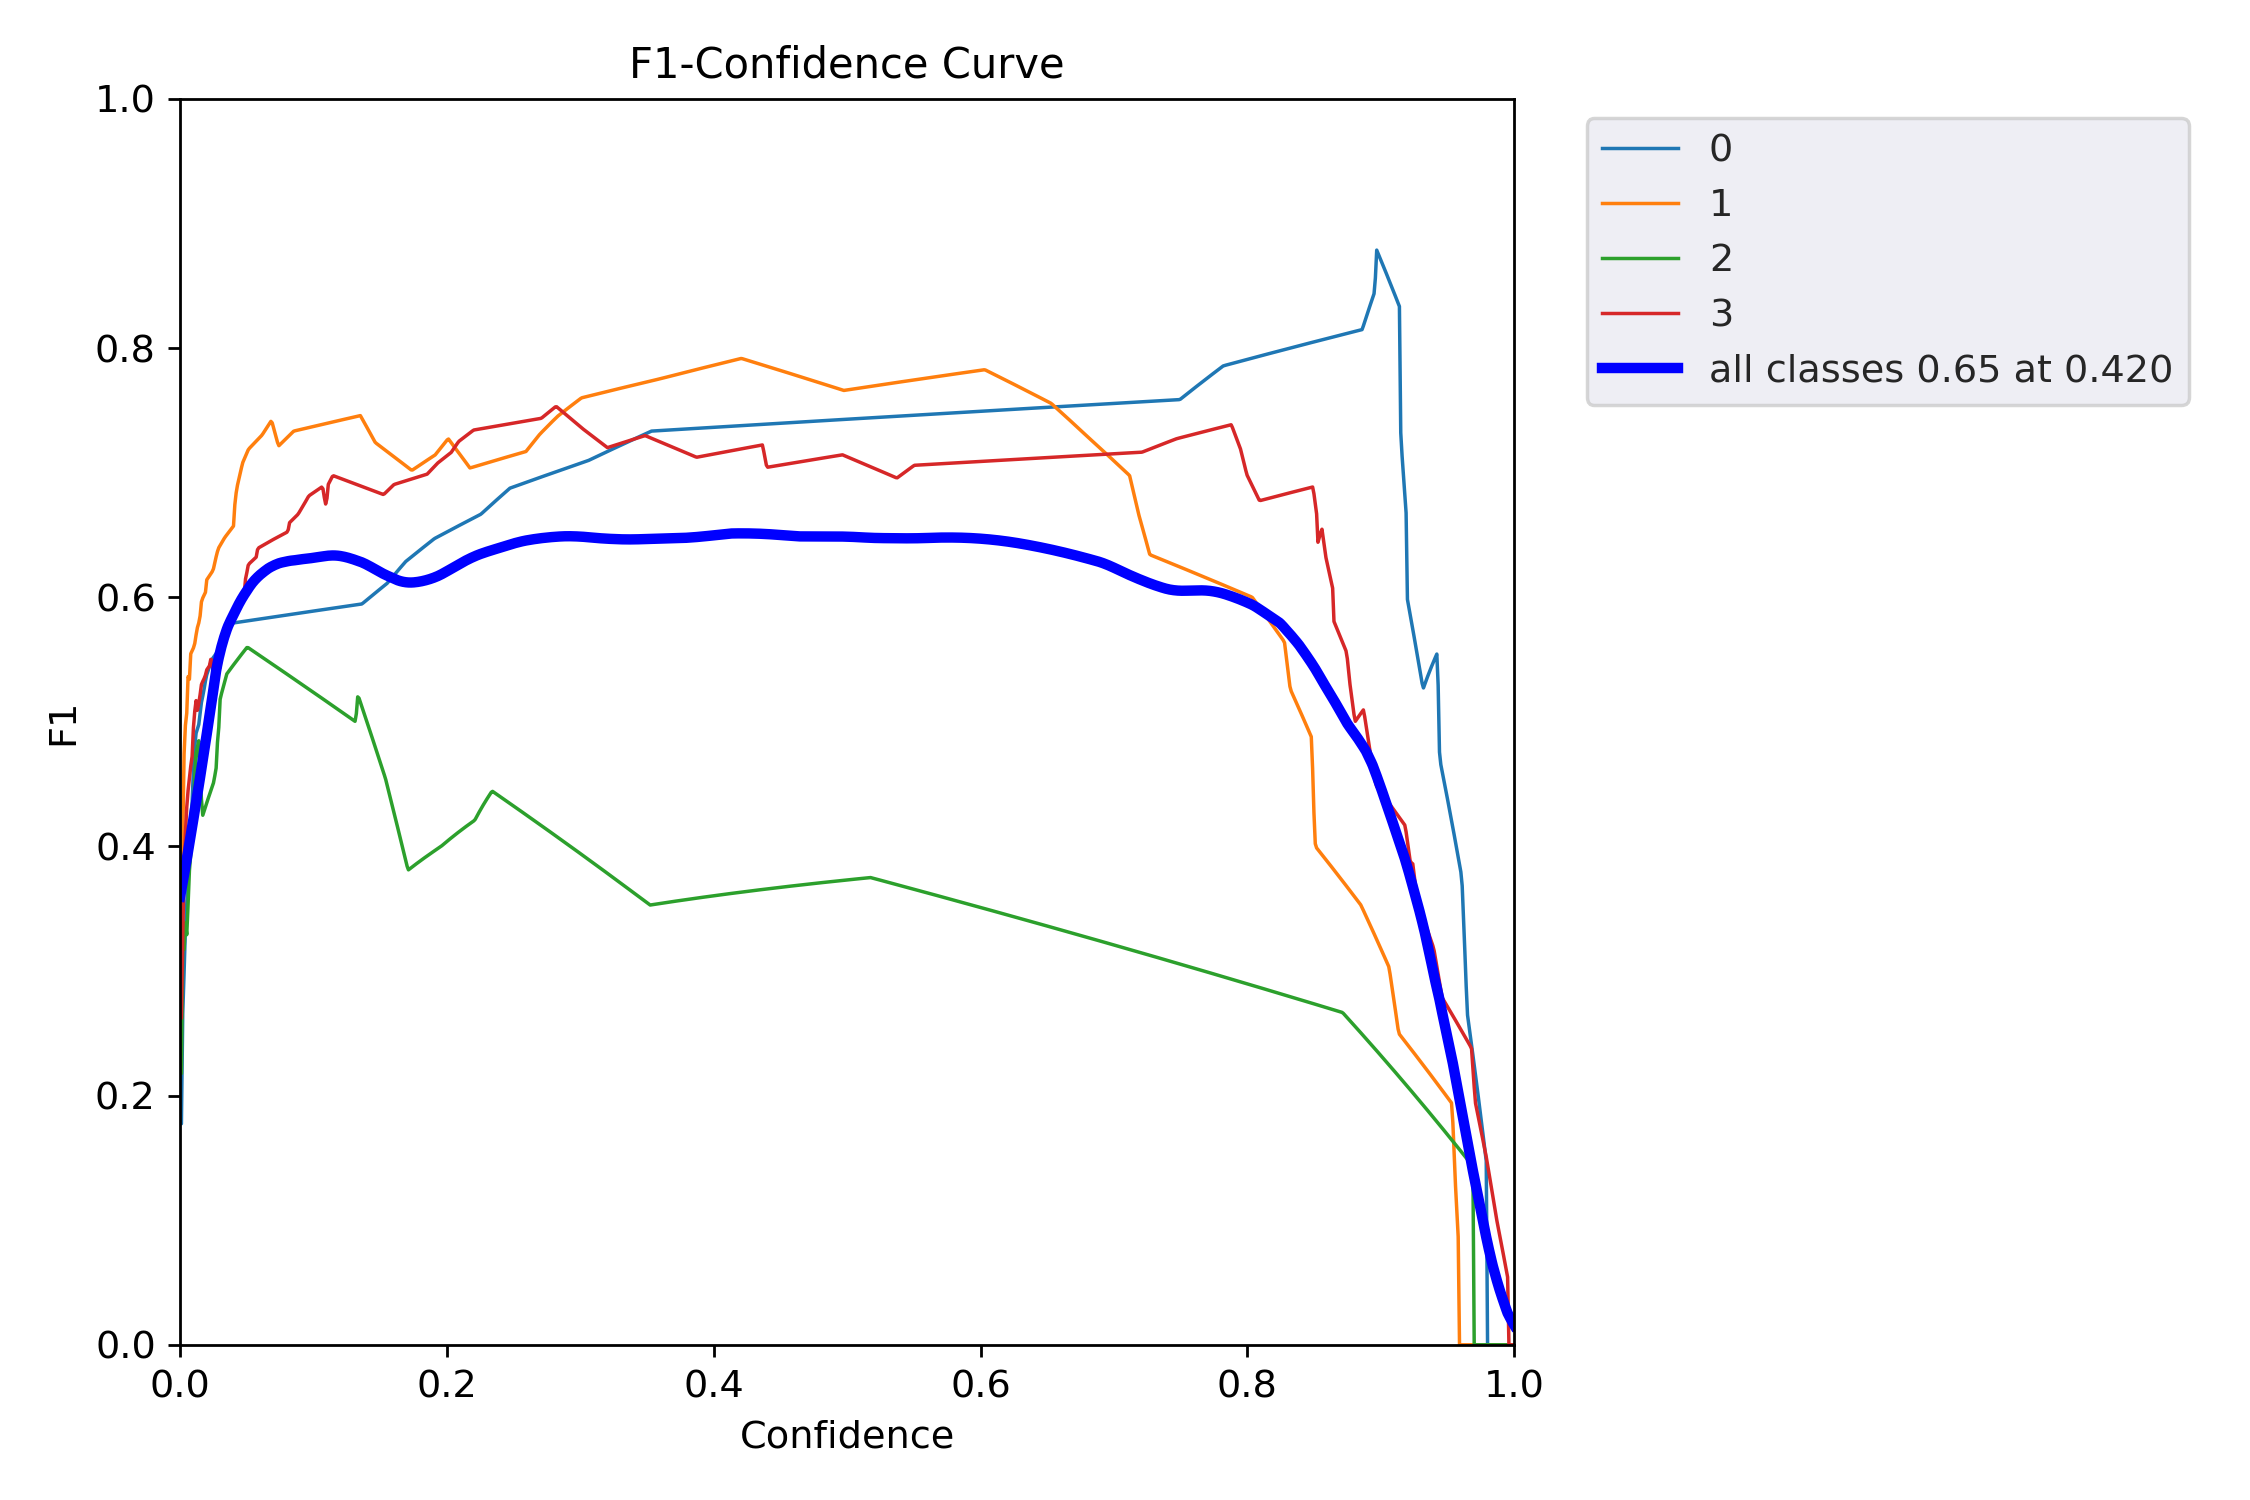

In [26]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/F1_curve.png", width=1000)

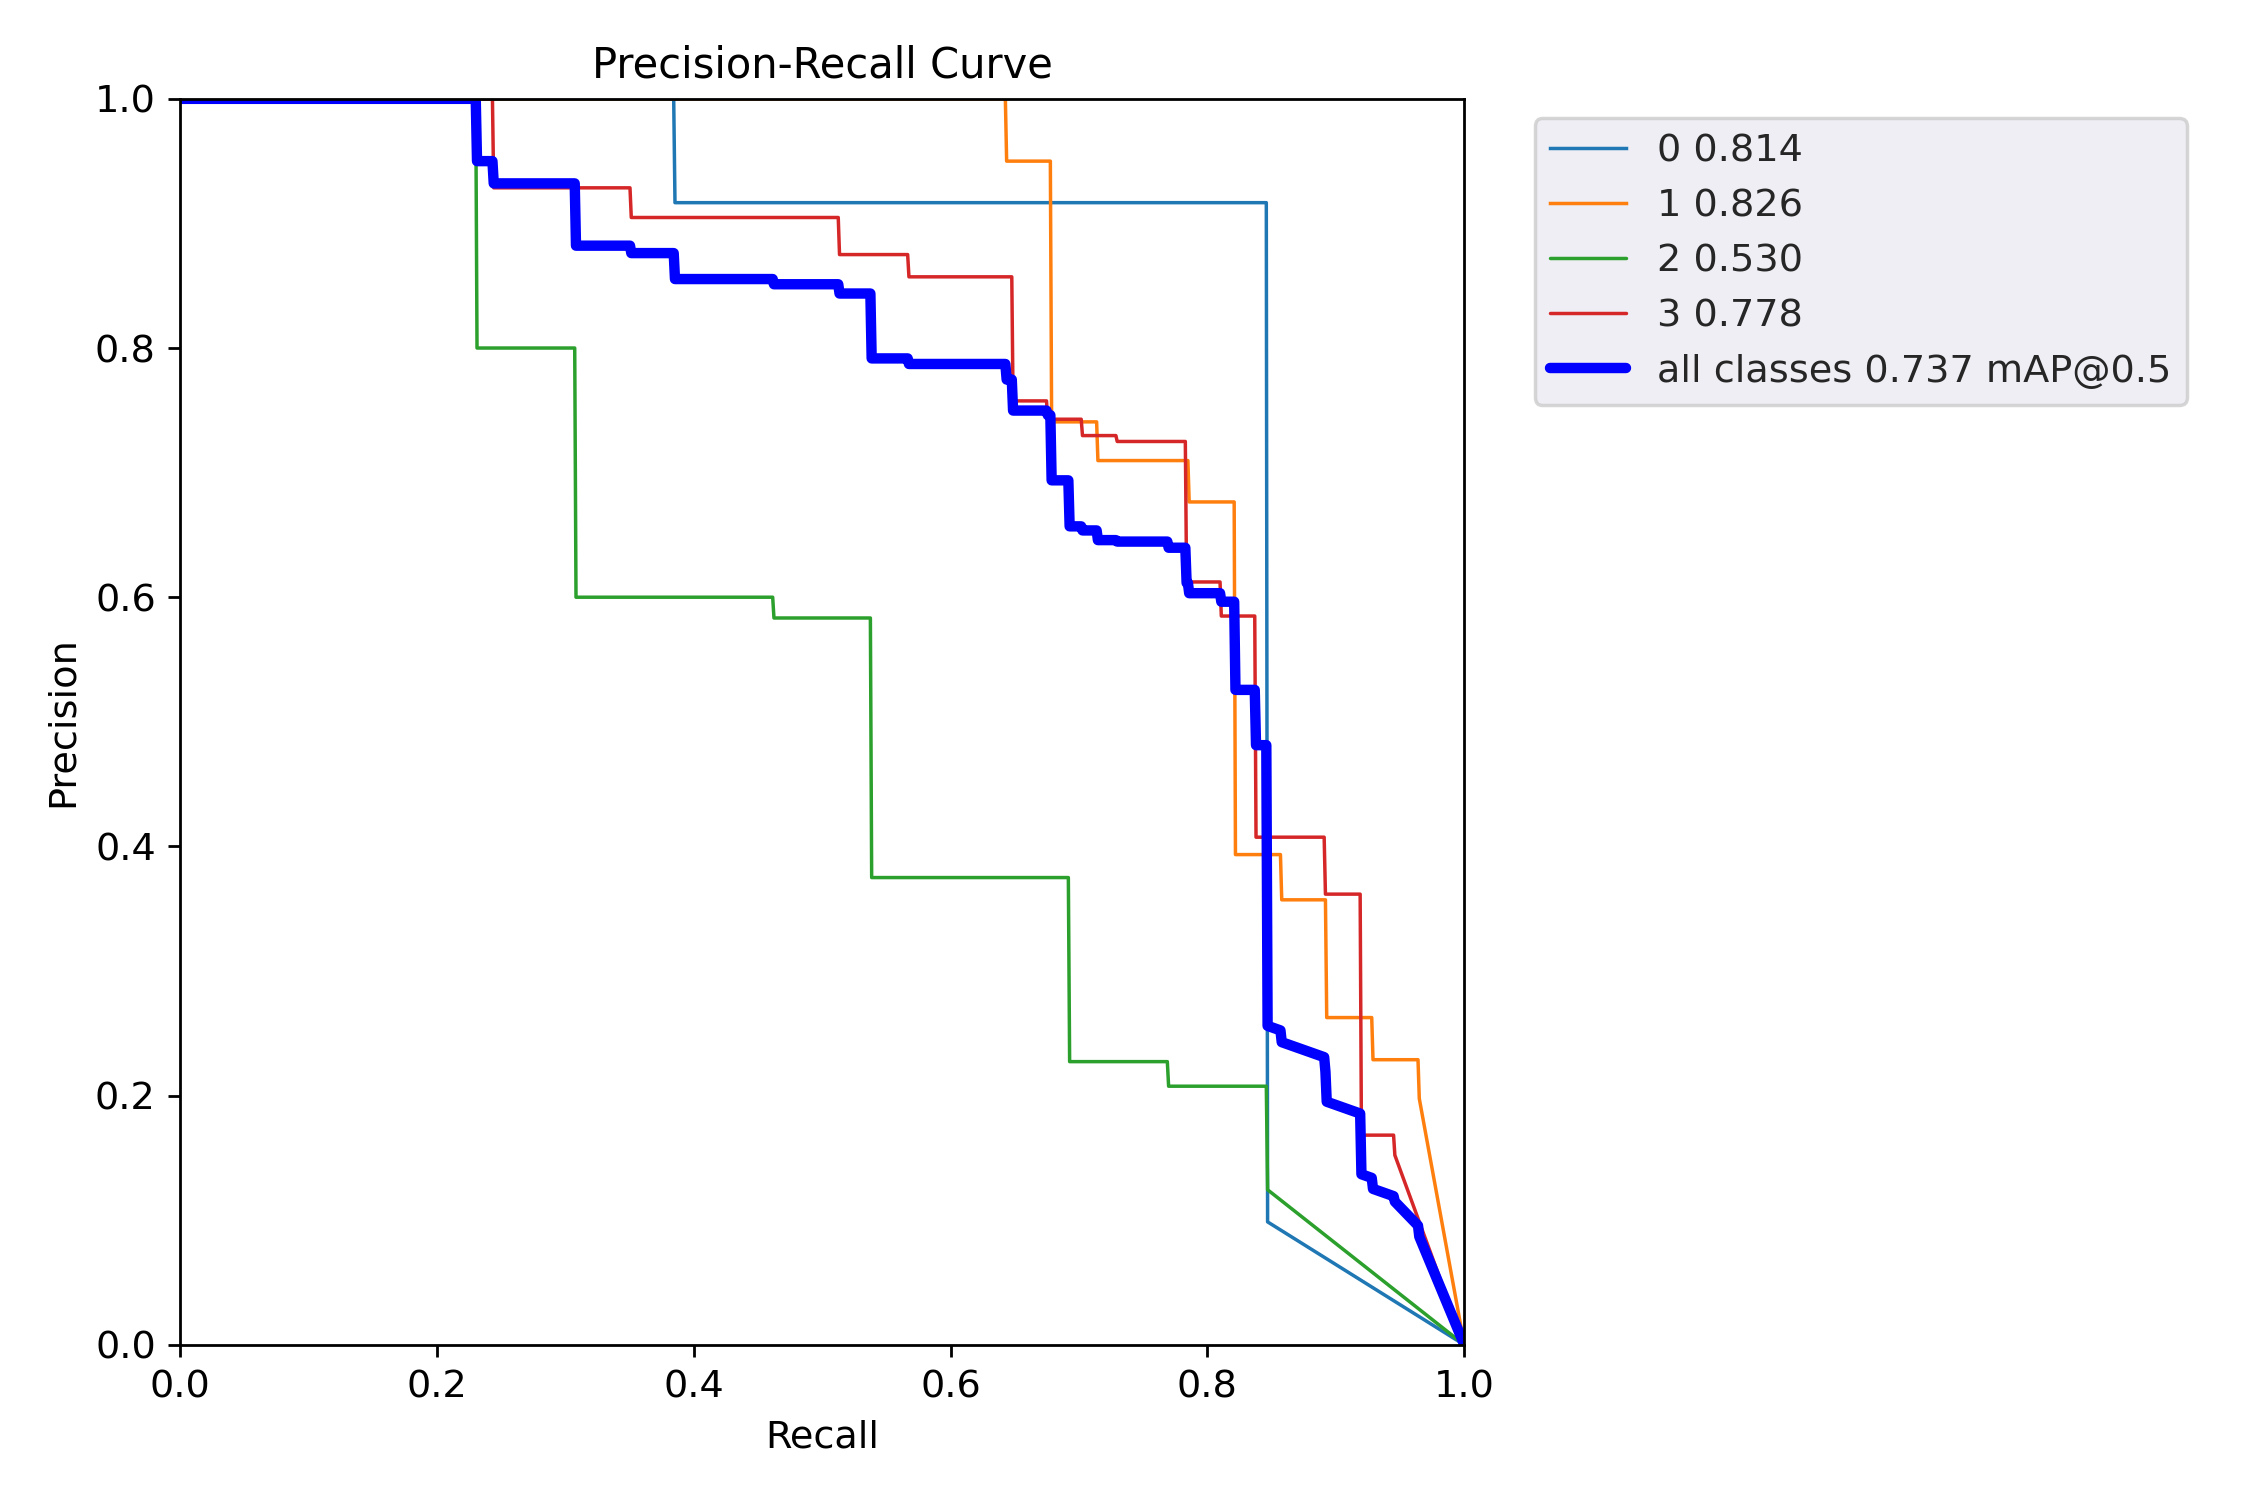

In [27]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/PR_curve.png", width=1000)

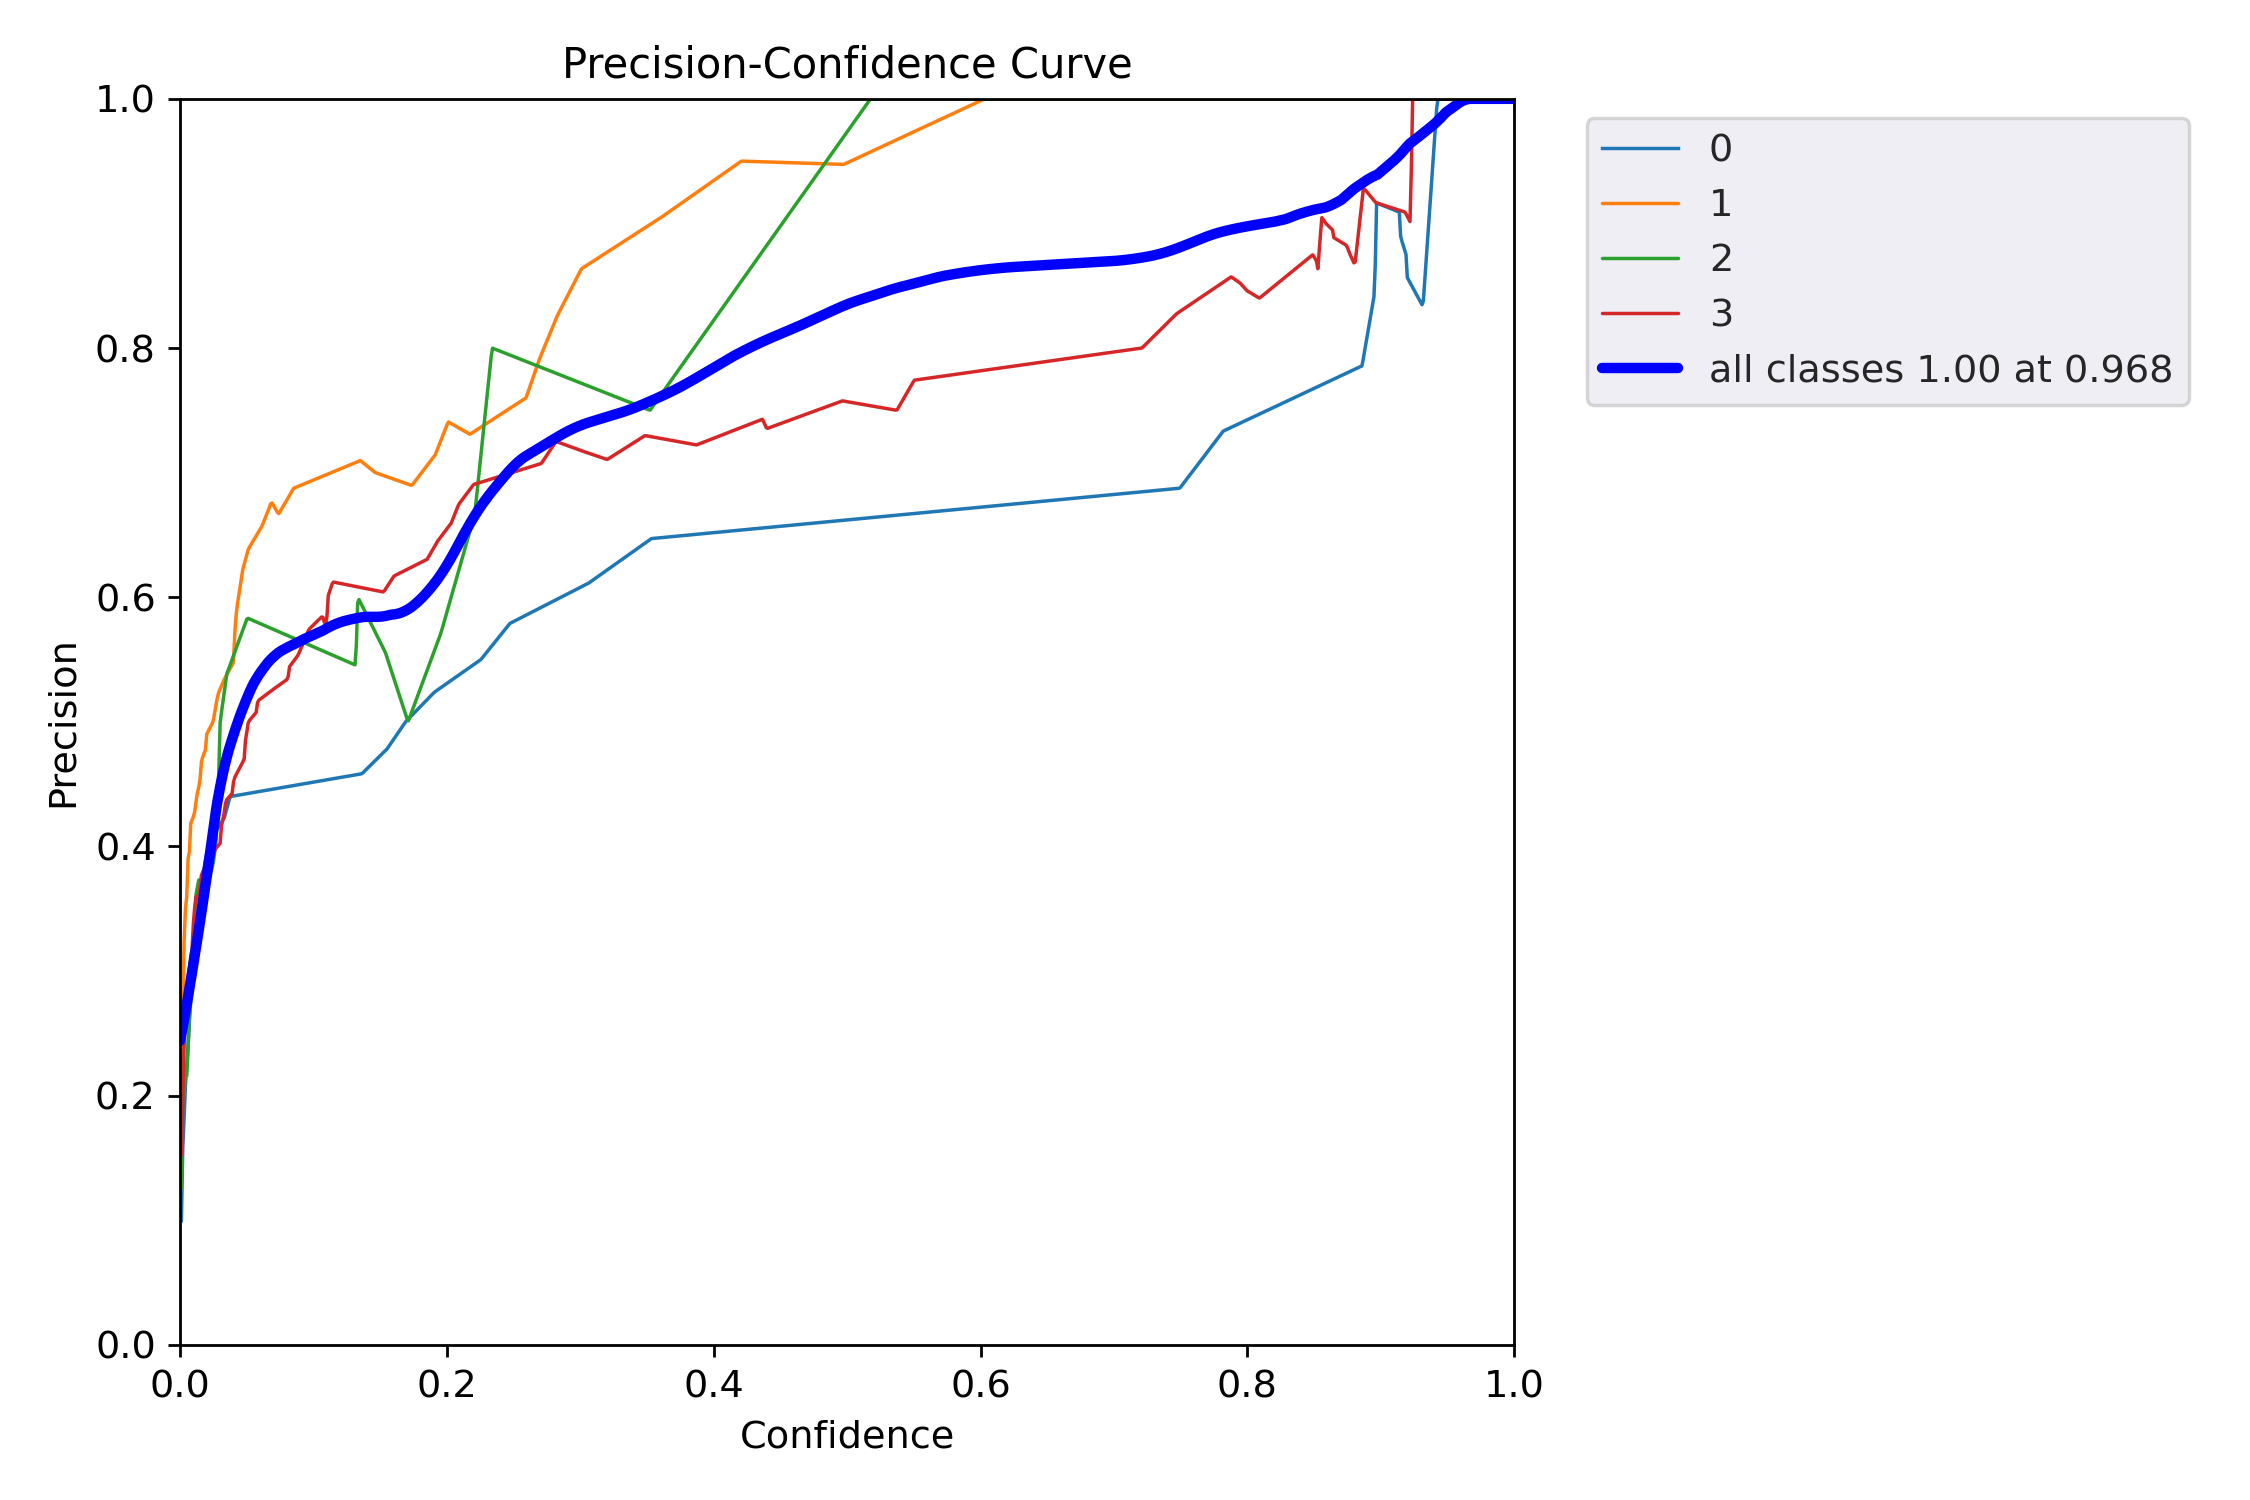

In [28]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/P_curve.png", width=1000)

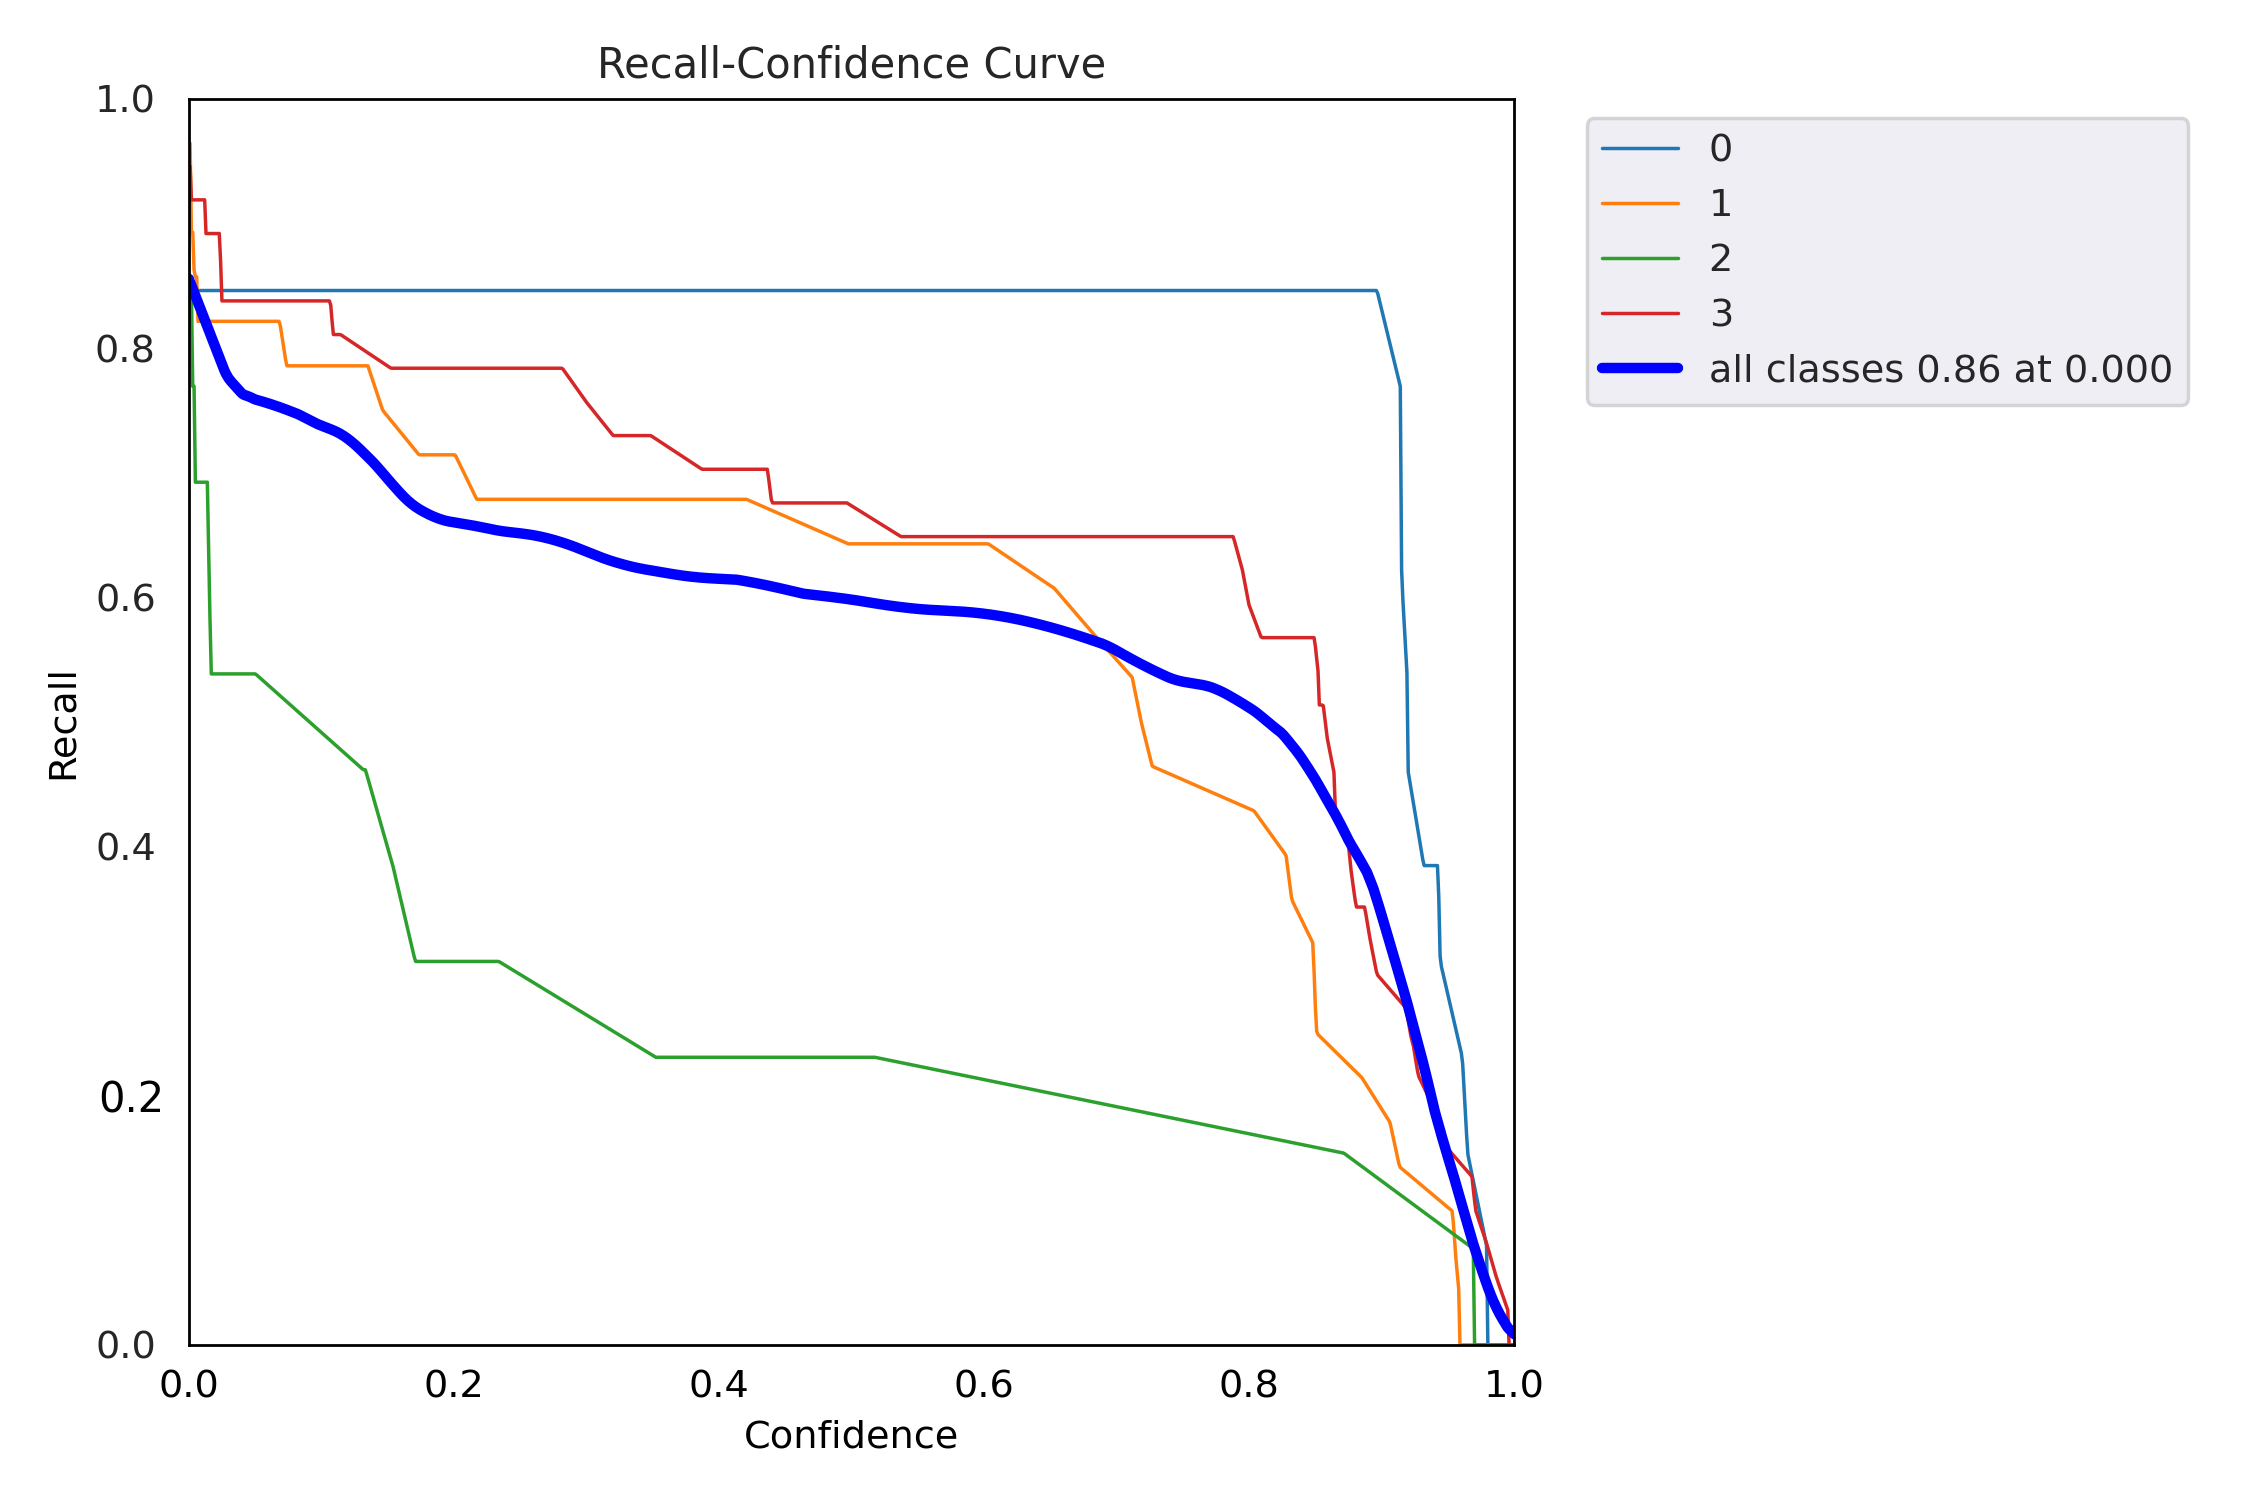

In [29]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/R_curve.png", width=1000)

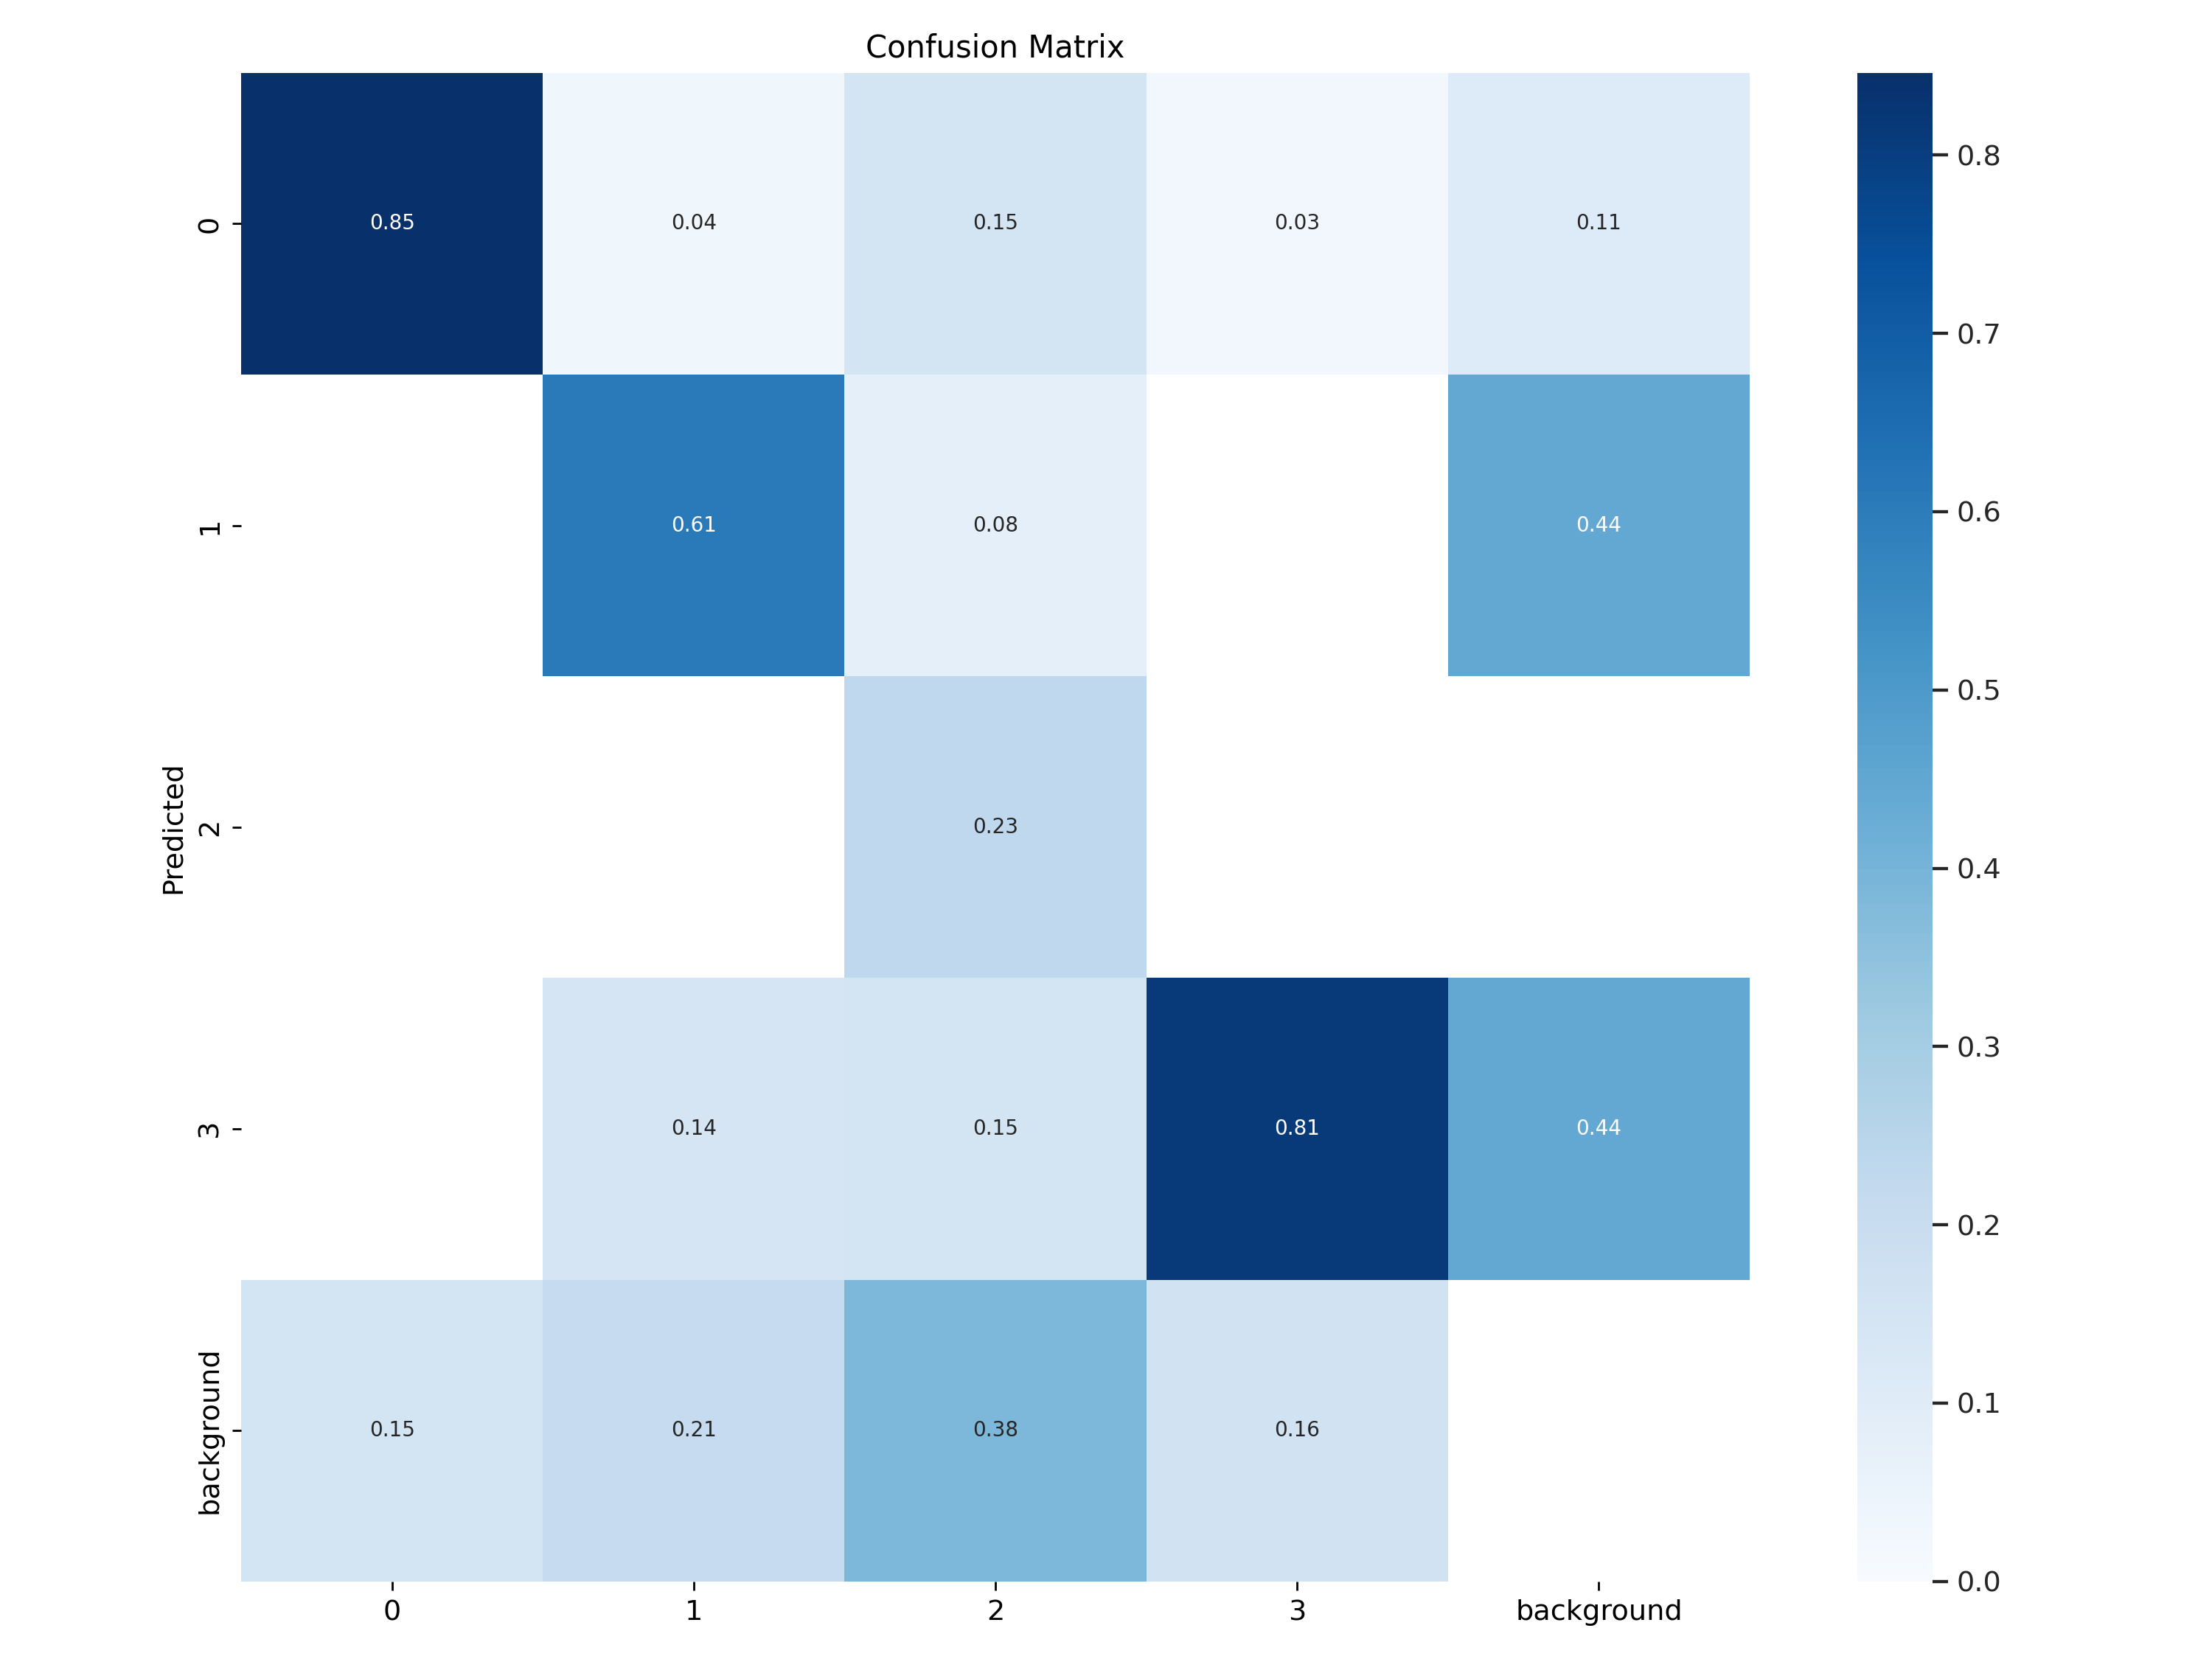

In [30]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/confusion_matrix.png", width=1000)

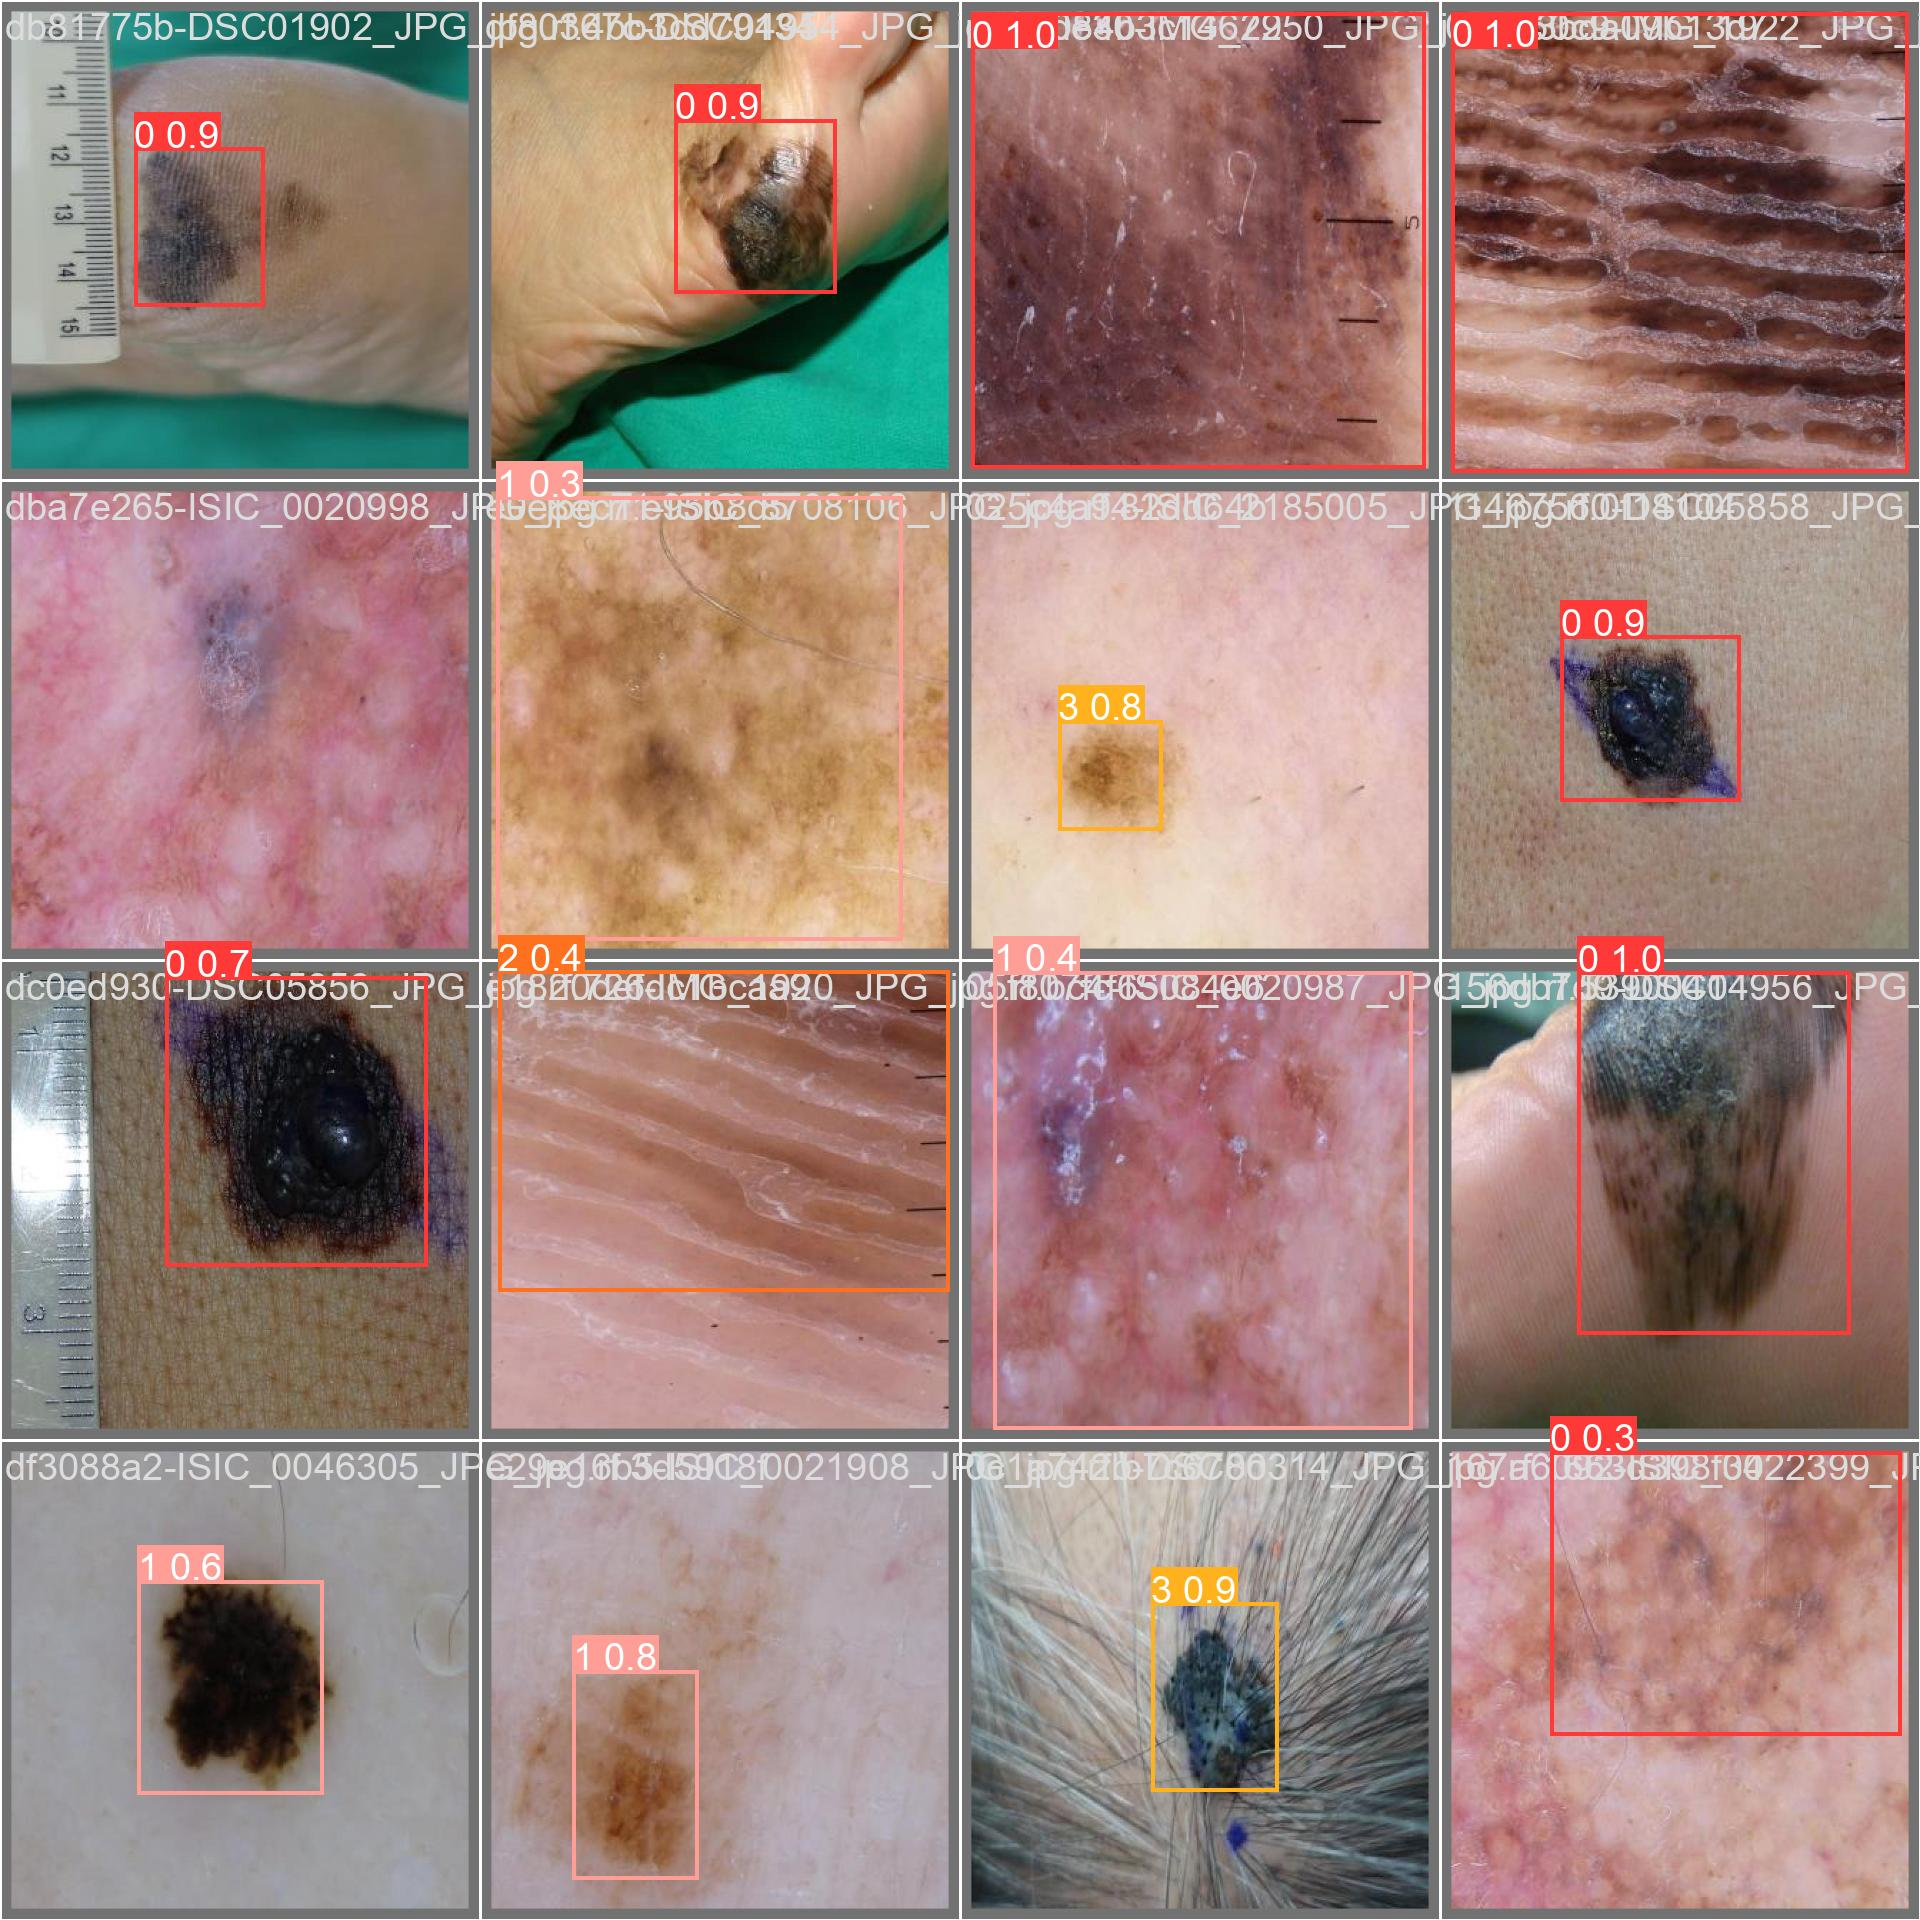

In [31]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/val_batch0_pred.jpg", width=1000)

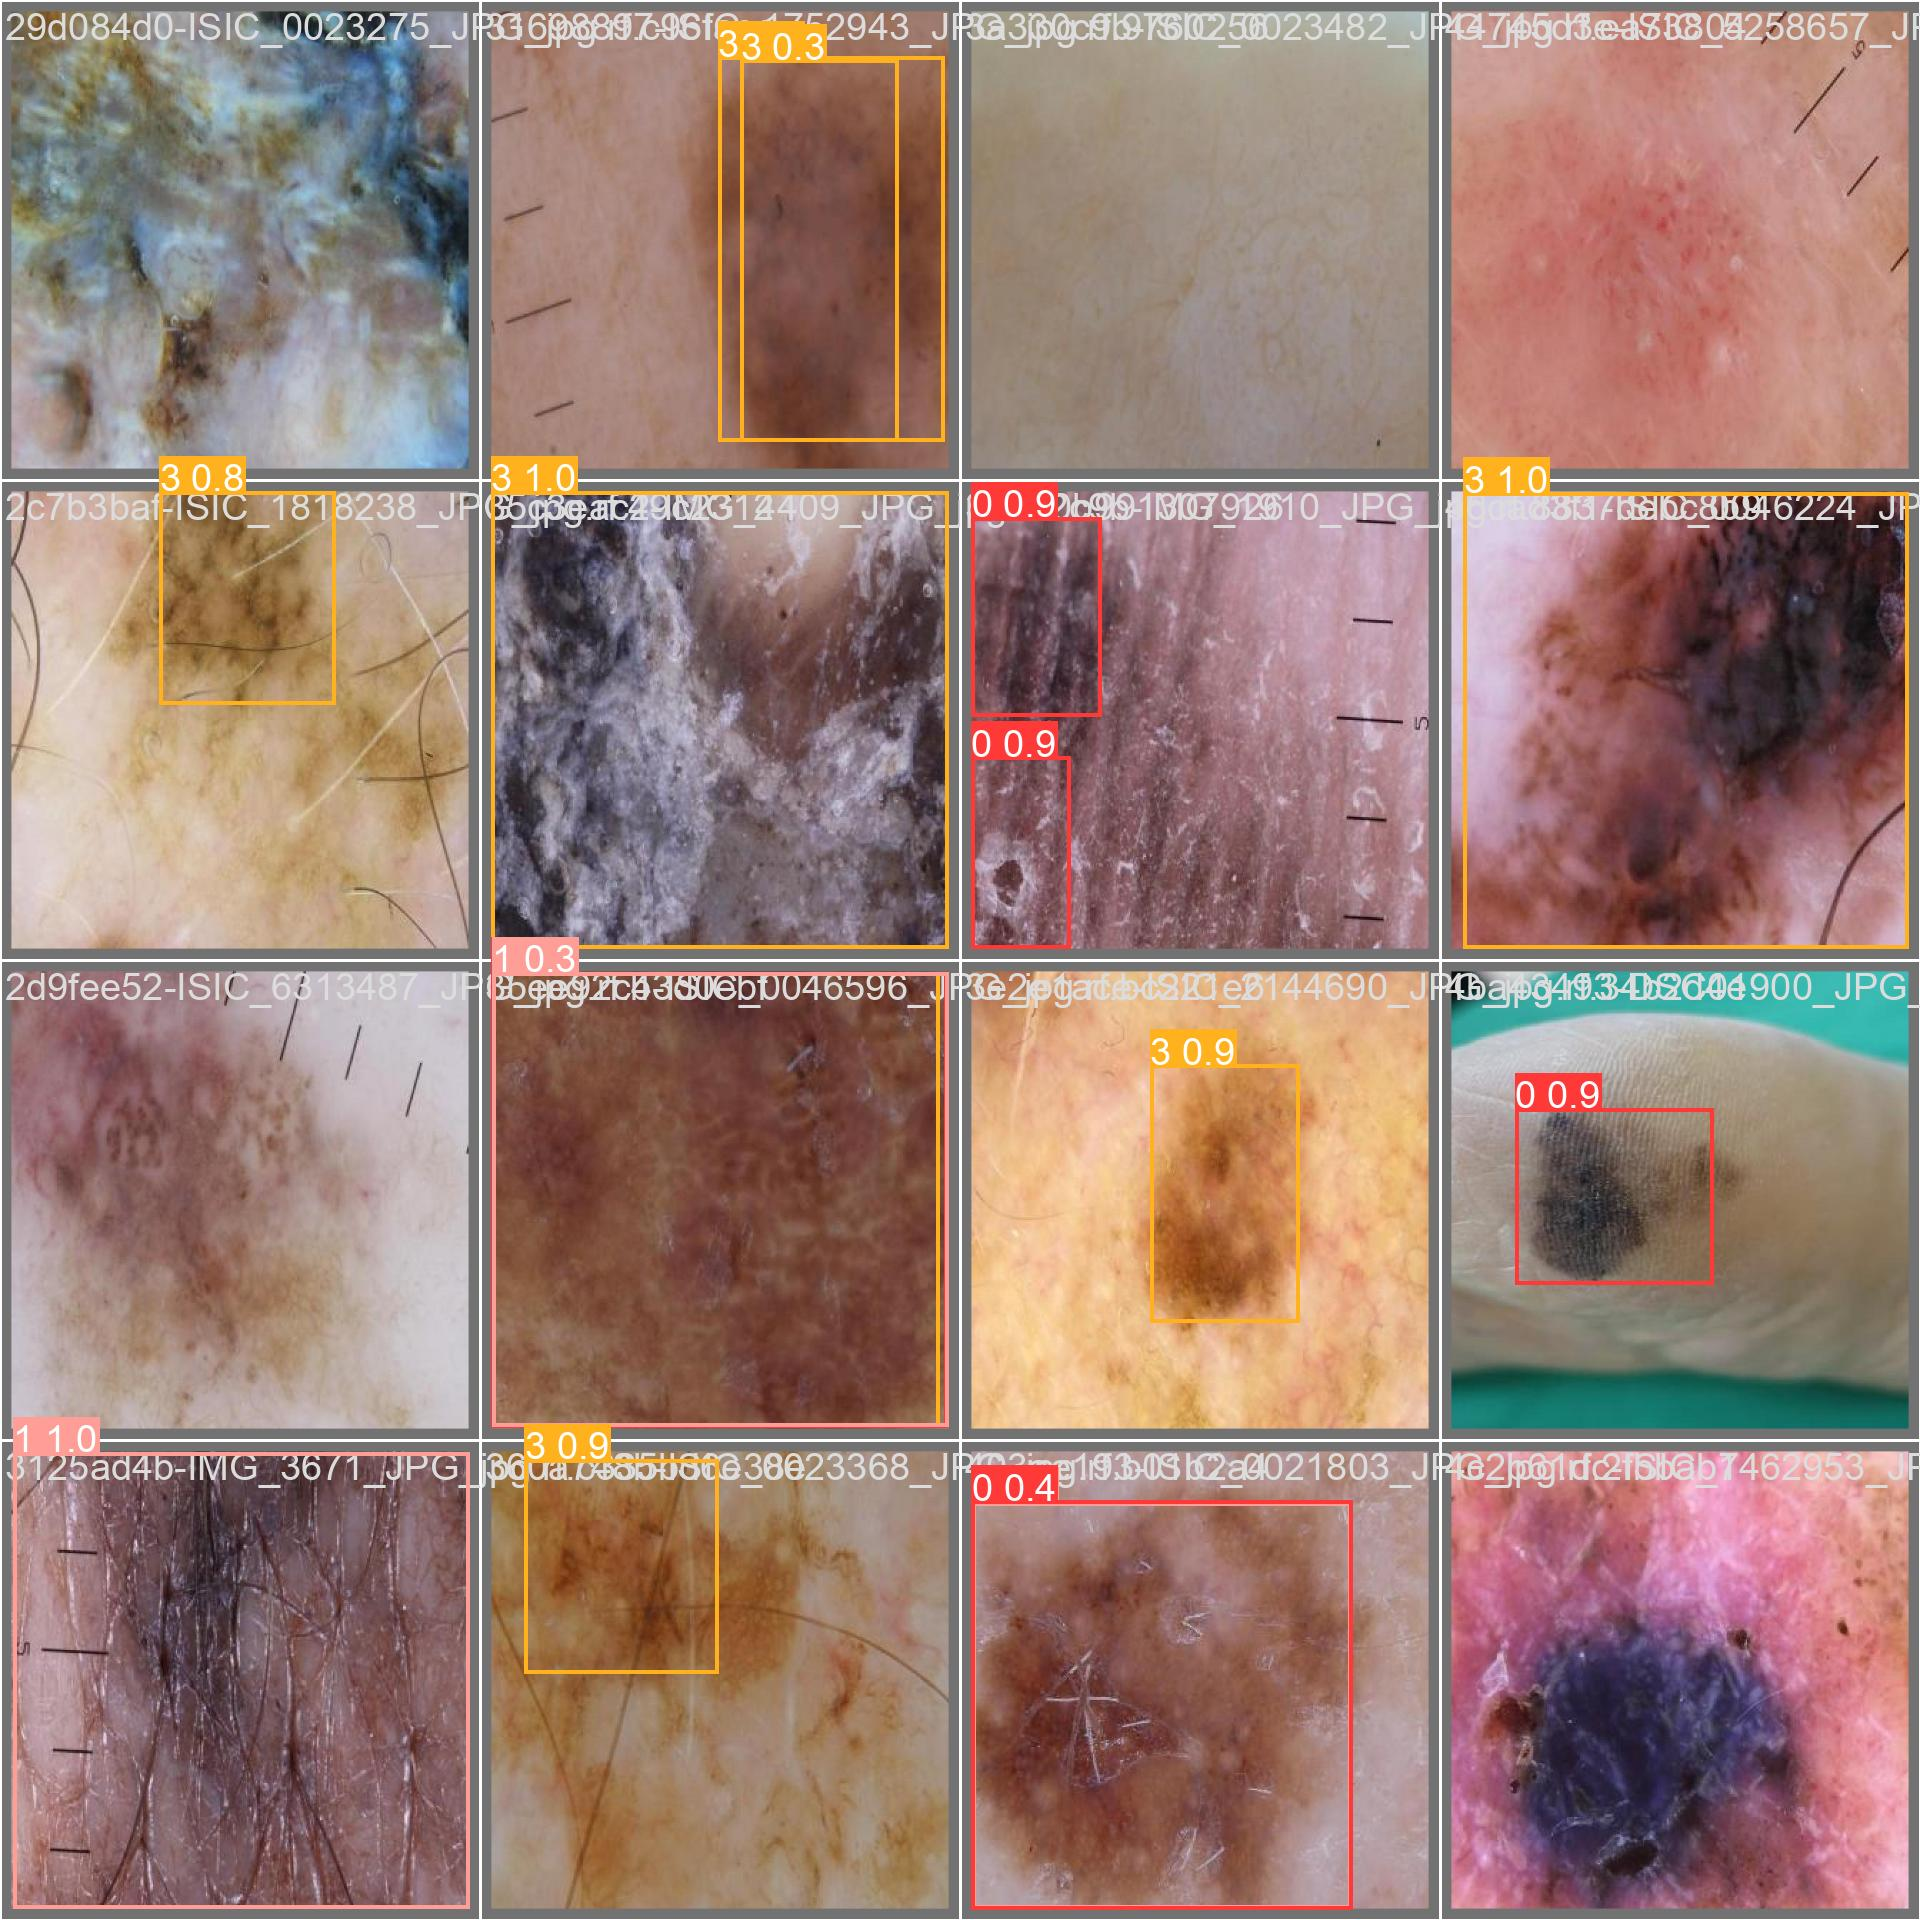

In [32]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/val_batch1_pred.jpg", width=1000)

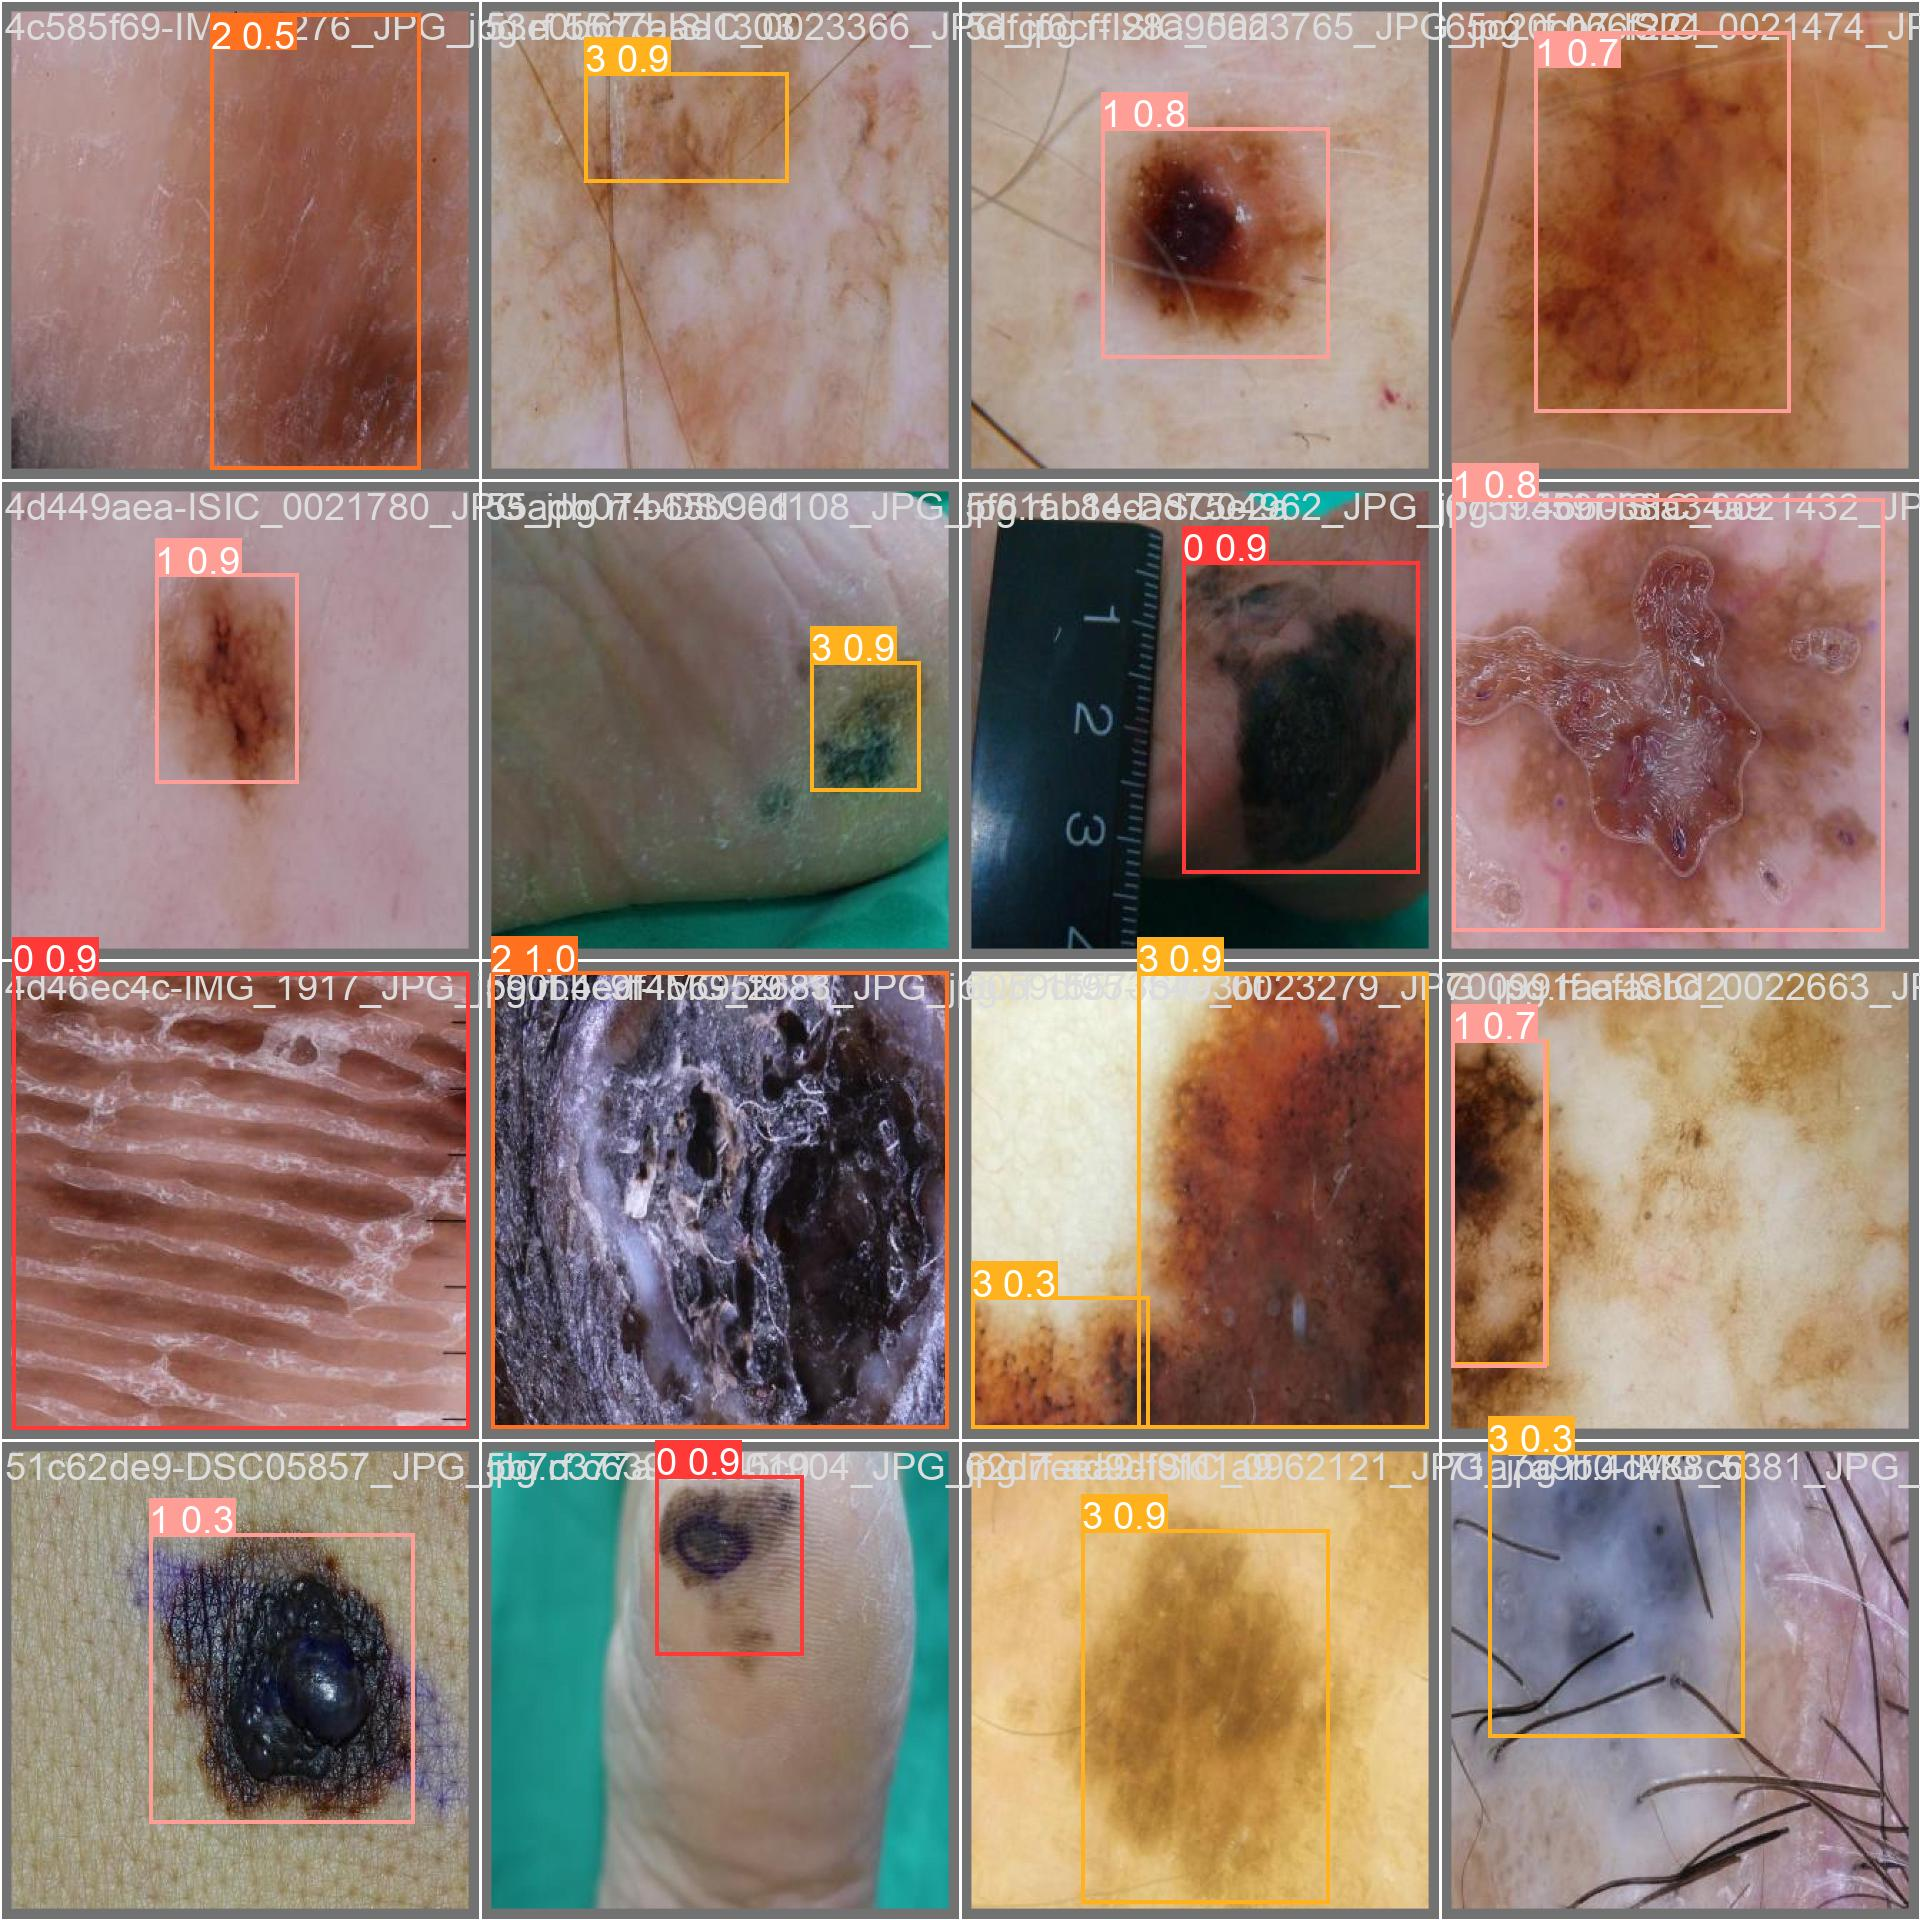

In [33]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/val/exp/val_batch2_pred.jpg", width=1000)